# Rocket landing: everything I tried, in order

This notebook goes through every model I tried for the rocket landing controller and compares them on the same 50 random starts.

- **Part 1** is my first set of attempts: fixing the outputs, clamping the thrust, a thrust on/off toggle, balancing the data, removing the past actuator values, more layers and the engine-off acceleration features.
- **Part 2** starts from the acceleration features, which made training and simulating painfully slow. I work out why, make it fast, then use the speed to test a lot more ideas: training tweaks, cheaper physics features, data augmentation, bigger networks and finally ensembles, which turned out to be the answer.

Every model goes into a `leaderboard` so the end of the notebook can compare them all in one table.

A note on the numbers: on a CPU the training is repeatable, the same seed gives exactly the same weights every time, so you should get the same numbers as the ones I quote. On a GPU some operations aren't deterministic, so your numbers will move around a bit. Either way, the seed changes the result a lot, which is why Part 2 trains several seeds of every model.

**Runtime:** Part 1 runs a grid search for each model. Part 2 trains `N_SEEDS` copies of each model and flies 50 flights with each one. With `N_SEEDS = 5`, one Part 2 model takes roughly 1.5-2 minutes, most of it in the simulator. Lower `N_SEEDS` for a quicker pass.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import importlib
import time
from collections import Counter
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from safetensors.torch import load_file, save_file
from torch import nn
from tqdm.auto import tqdm # This is just a progress bar for the training loop

# The simulator files, these need to be in the same folder as the notebook
from rocket_closed_loop import evaluate_closed_loop, evaluate_closed_loop_batch
from rocket_physics import Command
from rocket_runtime import scenario
from rocket_scoring import CONFIG

# Same lists as in the model files, I need them here to pick the right columns out of the csv
FEATURES = [
    "x", "y", "vx", "vy", "theta", "omega", "fuel_mass", "actual_thrust",
    "actual_gimbal", "wind_x", "wind_y", "air_density",
]
TARGETS = ["thrust", "gimbal"]

c:\Users\archi\Documents\programming\web\html\Archie-C.github.io\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
landings_path = Path("landings.csv")

seed = 42
np.random.seed(seed)
torch.manual_seed(seed)

# This is how many times I train each model in Part 2. More seeds make the comparisons fairer but it takes
# longer, so lower it if you just want a quick look.
N_SEEDS = 5

# I'm adding the device in and using a GPU so I can train faster (hopefully)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [4]:
# Load the landings from the path
landings = pd.read_csv(landings_path)
print(f"Loaded {len(landings):,} observations from {landings.run_id.nunique()} flights")

Loaded 104,992 observations from 1000 flights


In [5]:
# Splitting by whole flights, otherwise rows from the same flight end up in both train and test and the
# test score looks better than it really is.
TRAINING_SPLIT = 0.8
VALIDATION_SPLIT = 0.1
TEST_SPLIT = 0.1

run_ids = np.random.default_rng(seed).permutation(landings.run_id.unique())
train_end = int(TRAINING_SPLIT * len(run_ids))
val_end = int((TRAINING_SPLIT + VALIDATION_SPLIT) * len(run_ids))

train = landings[landings.run_id.isin(run_ids[:train_end])].copy()
val = landings[landings.run_id.isin(run_ids[train_end:val_end])].copy()
test = landings[landings.run_id.isin(run_ids[val_end:])].copy()

for name, frame in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name}: {frame.run_id.nunique()} flights, {len(frame):,} observations")

Train: 800 flights, 83,103 observations
Validation: 100 flights, 10,748 observations
Test: 100 flights, 11,141 observations


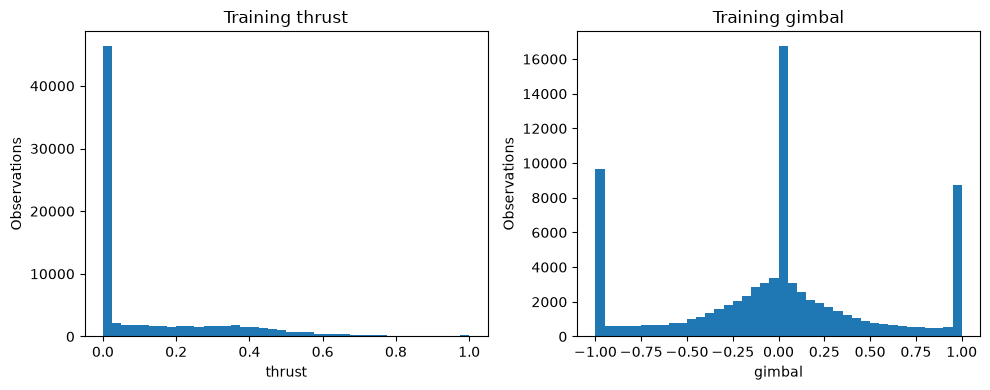

In [6]:
# These are continuous variables so we have to bin them first in order to plot a histogram.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, target in zip(axes, TARGETS):
    ax.hist(train[target], bins=40)
    ax.set(title=f"Training {target}", xlabel=target, ylabel="Observations")
plt.tight_layout()
plt.show()

#### Interpretation

There is an obvious imbalance here, the expert likes to use low thrust and hardly ever max thrust -> So it'll be hard for our model to learn max thrust behaviour regardless on the architecture. Gimbal looks better but still heavily imbalanced. We can't use class weighting here because there aren't classes, but we can do sampling. Before though, I should train the base model to see it's performance. I'm going to add some tweaks to the base training code though, as I also want to tune the model, so I'm actually making a realistic comparison and not comparing any new models to a weak baseline.

## Training and simulation code

I'm putting all of the training and simulation code here so that every model in the notebook uses exactly the same code. It has two speed-ups that I only found in Part 2: the features are computed **once** before training instead of on every batch, and the 50 test flights are simulated **together** instead of one at a time. Part 2 explains where they come from. Neither changes the results, only how long they take.

In [7]:
# Data prep & model tuning functions
def tensors(frame):
    x = frame[FEATURES].to_numpy(dtype=np.float32, copy=True)
    y = frame[TARGETS].to_numpy(dtype=np.float32, copy=True)
    return torch.from_numpy(x).to(device), torch.from_numpy(y).to(device) # I added two device calls here, otherwise the model and the data are on different devices and pytorch will error.

train_x, train_y = tensors(train)
val_x, val_y = tensors(val)
test_x, test_y = tensors(test)

# Just some hyperparameters to try, there will be 20 combinations here, so 20 runs.
batch_sizes = [256, 512, 1024, 2048]
learning_rates = [1e-4, 5e-4, 1e-3, 5e-3, 1e-2]
max_epochs = 200
early_stopping_patience = 10
optimiser = torch.optim.Adam # Don't init the optimiser here, it needs to be initialised with the model parameters each time.
smooth_l1 = nn.SmoothL1Loss() # This is the same as Huber loss, which is less sensitive to outliers than MSE loss.

# This is a wrapper so it works with a later loss function that needs to access the model's outputs directly.
def loss_fn(model, x, y):
    return smooth_l1(model(x), y)

In [8]:
# None of my features() functions have any weights, so they give exactly the same answer every epoch.
# So instead of working them out again for every batch, I work them out once for the whole dataset here.
def precompute_features(model_factory, *xs):
    """Runs the model's features() once over the whole tensors.
    If the model doesn't have a features() function, the raw data comes back unchanged."""
    probe = model_factory().to(device)
    if not hasattr(probe, "features"):
        return xs
    with torch.no_grad():
        # Done in chunks so a big dataset doesn't run out of memory on the GPU
        return tuple(torch.cat([probe.features(chunk) for chunk in x.split(65536)]) for x in xs)

def skip_features(model):
    """Makes the model skip its features() function, because the data going in is already the features.
    This only changes this one model object (it hides the method), so the weights and the model file are untouched."""
    if hasattr(model, "features"):
        model.features = lambda features: features
    return model

In [9]:
# I'll write a function so I can use it later
def tune_model(model_factory, train_x, train_y, val_x, val_y, optimiser_class, loss_fn, learning_rates, batch_sizes, max_epochs, early_stopping_patience, model_name="BaseModel"):
    """Grid search over learning rate and batch size, with early stopping on the validation loss.

    Returns the model with the lowest validation loss, a table with one row per run (best first),
    and the per-epoch losses for each (learning_rate, batch_size).
    """
    results, histories = [], {}
    overall_best_loss = float("inf")
    overall_best_state = None

    # This is the new bit: the features are worked out once here instead of on every batch
    train_f, val_f = precompute_features(model_factory, train_x, val_x)

    runs_bar = tqdm(total=len(learning_rates) * len(batch_sizes), desc=model_name, unit="run") # Set up the progress bar

    for learning_rate in learning_rates:
        for batch_size in batch_sizes:
            # Use the same seed for every run so that they differ only in their hyperparameters.
            torch.manual_seed(seed)
            # Create a new model for each combination of hyperparameters. skip_features means it uses the features from above.
            model = skip_features(model_factory().to(device))
            # Fused Adam is faster on GPUs, but it only works with CUDA so I only switch it on there.
            optimiser = optimiser_class(model.parameters(), lr=learning_rate, fused=device.type == "cuda")

            best_val_loss = float("inf")
            best_epoch = 0
            epochs_without_improvement = 0
            history = {"train": [], "val": []}

            # Early stopping usually ends a run well before max_epochs, so this bar often will not fill.
            epochs_bar = tqdm(range(1, max_epochs + 1), desc=f"lr {learning_rate:g}, batch size {batch_size}", unit="epoch", leave=False)
            for epoch in epochs_bar:
                model.train()
                total_loss = torch.zeros((), device=device) # Keep this on the device, calling .item() on every batch is slow.

                # All of the data is already on the device, so indexing a whole batch at once is much
                # faster than a DataLoader, which would fetch the rows one at a time.
                for batch in torch.randperm(len(train_f), device=device).split(batch_size):
                    optimiser.zero_grad()
                    loss = loss_fn(model, train_f[batch], train_y[batch])
                    loss.backward()
                    optimiser.step()
                    total_loss += loss.detach() * len(batch)

                model.eval()
                with torch.no_grad():
                    val_loss = loss_fn(model, val_f, val_y).item()

                history["train"].append(total_loss.item() / len(train_f))
                history["val"].append(val_loss)

                if val_loss < best_val_loss:
                    best_val_loss = val_loss
                    best_epoch = epoch
                    epochs_without_improvement = 0
                    # Clone the weights from the best epoch, otherwise later epochs would overwrite them.
                    if val_loss < overall_best_loss:
                        overall_best_loss = val_loss
                        overall_best_state = {name: value.detach().clone() for name, value in model.state_dict().items()}
                else:
                    epochs_without_improvement += 1
                    if epochs_without_improvement >= early_stopping_patience:
                        break

                epochs_bar.set_postfix(val=f"{val_loss:.5f}", best=f"{best_val_loss:.5f}", patience=f"{epochs_without_improvement}/{early_stopping_patience}")

            epochs_bar.close()

            histories[(learning_rate, batch_size)] = history
            results.append({
                "model": model_name,
                "learning_rate": learning_rate,
                "batch_size": batch_size,
                "best_val_loss": best_val_loss,
                "best_epoch": best_epoch,
                "epochs_run": epoch,
            })
            tqdm.write(f"{model_name} | lr {learning_rate:g}, batch size {batch_size} | best validation loss {best_val_loss:.5f} at epoch {best_epoch} (ran {epoch})")
            runs_bar.update()
            runs_bar.set_postfix(best=f"{overall_best_loss:.5f}")

    runs_bar.close()

    if overall_best_state is None:
        raise RuntimeError("No run produced a finite validation loss.")

    # Making a fresh model here so features() works normally again. The simulator and the export both need
    # the model to take the raw observations.
    best_model = model_factory().to(device)
    best_model.load_state_dict(overall_best_state)
    best_model.eval()

    results = pd.DataFrame(results).sort_values("best_val_loss", ignore_index=True)
    return best_model, results, histories

In [10]:
# Putting the evaluation code in a function so it can be reused
def evaluate_model(model, test_x, test_y):
    model.eval()
    with torch.no_grad():
        predictions = model(test_x).detach().cpu().numpy()

    test_y_cpu = test_y.detach().cpu().numpy()

    errors = np.abs(predictions - test_y_cpu)
    for i, target in enumerate(TARGETS):
        print(f"{target} test MAE: {errors[:, i].mean():.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for i, (ax, target) in enumerate(zip(axes, TARGETS)):
        ax.scatter(test_y_cpu[::10, i], predictions[::10, i], s=3, alpha=0.2)
        ax.set(xlabel="Expert", ylabel="Prediction", title=target)
    plt.tight_layout()
    plt.show()

In [11]:
# Simulator code
# This is the original one flight at a time version. I only use it in Part 2 to show how much faster the batched version is.
def simulate(model, scenario_name, *, seed=None):
    model.eval()
    device = next(model.parameters()).device

    def policy(observation):
        with torch.inference_mode():
            x = torch.tensor(observation, dtype=torch.float32, device=device).unsqueeze(0)
            output = model(x)
        if not isinstance(output, torch.Tensor) or tuple(output.shape) != (1, 2):
            raise ValueError("The model must return a tensor with shape (1, 2).")
        thrust, gimbal = output[0].tolist()
        return Command(thrust, gimbal)

    if scenario_name == "random_start":
        scenario_name = "demo_descent"
        parameters, initial_state = scenario(scenario_name)
        rng = np.random.default_rng(seed)
        initial_state = replace(initial_state, x=float(rng.uniform(-40.0, 40.0)), y=float(rng.uniform(350.0, 850.0)))
    else:
        parameters, initial_state = scenario(scenario_name)

    result = evaluate_closed_loop(policy, initial_state, parameters, scenario_name, control_mode="continuous")
    if result["replay"]["status"] == "error":
        raise ValueError(result["termination_reason"])
    return result


def random_start_flights(seeds):
    """Makes the same random starts as simulate(model, "random_start", seed=seed), so they are the same flights as before."""
    flights = []
    for flight_seed in seeds:
        parameters, initial_state = scenario("demo_descent")
        rng = np.random.default_rng(flight_seed)
        initial_state = replace(initial_state, x=float(rng.uniform(-40.0, 40.0)), y=float(rng.uniform(350.0, 850.0)))
        flights.append(dict(initial_state=initial_state, parameters=parameters, scenario_id="demo_descent"))
    return flights


# This flies all of the flights at the same time. Every 0.1 s the model gets one batch with every flight that's still
# in the air, instead of being called once per flight per step. The model is tiny, so one call with 50 rows takes
# about as long as one call with 1 row.
def simulate_batch(model, seeds, *, record=True):
    model.eval()
    model_device = next(model.parameters()).device

    def policy(observations):
        with torch.inference_mode():
            output = model(torch.as_tensor(observations, dtype=torch.float32, device=model_device))
        if not isinstance(output, torch.Tensor) or tuple(output.shape) != (len(observations), 2):
            raise ValueError("The model must return a tensor with shape (batch, 2).")
        # The simulator wants one Command per flight
        return [Command(thrust, gimbal) for thrust, gimbal in output.tolist()]

    seeds = list(seeds)
    results = evaluate_closed_loop_batch(policy, random_start_flights(seeds), record=record)
    for result in results:
        if result["status"] == "error":
            raise ValueError(result["termination_reason"])
    return dict(zip(seeds, results))

In [12]:
# I'm keeping a list of every model I fly so I can compare them all at the end
leaderboard = []

# Run a bunch of random simulations to get a good idea about performance
def run_sims(model, n_flights=50, n_plots=6, first_seed=42, name=None, step=""):
    simulation_results = simulate_batch(model, range(first_seed, first_seed + n_flights))

    rows = []
    for flight_seed, result in simulation_results.items():
        scoring = result["scoring"]
        snapshots = result["replay"]["snapshots"]
        # The last state is the touchdown, or wherever the rocket was when time ran out.
        final = snapshots[-1]["state"]
        # Touchdown errors are None if the rocket never made contact.
        errors = scoring["errors"]
        rows.append({
            "Seed": flight_seed,
            "Start x (m)": snapshots[0]["state"]["x"],
            "Start height (m)": snapshots[0]["state"]["y"],
            "Score / 100": scoring["score"],
            "Success": scoring["success"],
            # Mean normalised touchdown error: 0 is perfect, 1 means every limit was reached.
            "Touchdown error": np.mean(list(errors.values())) if errors else np.inf,
            "Final x (m)": final["x"],
            "Final height (m)": final["y"],
            "vx (m/s)": final["vx"],
            "vy (m/s)": final["vy"],
            "Tilt (deg)": np.degrees(final["theta"]),
            "Angular rate (deg/s)": np.degrees(final["omega"]),
            "Fuel left (kg)": final["fuel"],
            "Simulation time (s)": snapshots[-1]["time"],
            "Landing feedback": "; ".join(scoring["reasons"]) or "Safe landing",
        })

    # Best flights first. Failed flights all score 0, so touchdown error ranks those.
    summary = pd.DataFrame(rows).sort_values(["Score / 100", "Touchdown error"], ascending=[False, True], ignore_index=True)

    print(f"Flights: {len(summary)}")
    print(f"Mean score: {summary['Score / 100'].mean():.2f} / 100")
    print(f"Landing success: {summary['Success'].sum()}/{len(summary)} ({100 * summary['Success'].mean():.1f}%)")
    if name is not None:
        # Only one trained model here, so the mean, min and max are all the same number
        landed = int(summary["Success"].sum())
        leaderboard.append({"Step": step, "Model": name, "Seeds": 1, "Mean landed": landed, "Min": landed, "Max": landed, "Val loss": np.nan})

    # A flight can fail for several reasons, so these counts can add up to more than n_flights.
    reasons = pd.Series([reason for result in simulation_results.values() for reason in result["scoring"]["reasons"]], dtype=object)
    if len(reasons):
        display(reasons.value_counts().rename_axis("Failure reason").to_frame("Flights"))

    # Pick flights evenly spaced through the ranking, including the best and the worst.
    selected = summary.iloc[np.linspace(0, len(summary) - 1, min(n_plots, len(summary))).round().astype(int)]
    overview = ["Seed", "Start x (m)", "Start height (m)", "Score / 100", "Touchdown error", "Simulation time (s)", "Landing feedback"]
    final_state = ["Seed", "Final x (m)", "Final height (m)", "vx (m/s)", "vy (m/s)", "Tilt (deg)", "Angular rate (deg/s)", "Fuel left (kg)"]
    display(selected[overview].round(2))
    print(
        f"Final state. Safe landing limits: |vx| <= {CONFIG.max_horizontal_speed} m/s, "
        f"-{CONFIG.max_descent} <= vy <= 0 m/s, |tilt| <= {np.degrees(CONFIG.max_tilt):.1f} deg, "
        f"|angular rate| <= {np.degrees(CONFIG.max_angular_rate):.1f} deg/s"
    )
    display(selected[final_state].round(2))

    n_cols = 3
    n_rows = int(np.ceil(len(selected) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), sharex=True, sharey=True, squeeze=False)
    for ax, (rank, row) in zip(axes.flat, selected.iterrows()):
        states = [frame["state"] for frame in simulation_results[row["Seed"]]["replay"]["snapshots"]]
        ax.plot([state["x"] for state in states], [state["y"] for state in states], label="Flight path")
        ax.plot(states[0]["x"], states[0]["y"], "o", color="tab:blue", label="Start")
        ax.plot([CONFIG.pad_left, CONFIG.pad_right], [CONFIG.pad_height] * 2, color="black", linewidth=3, label="Landing pad")
        outcome = "landed" if row["Success"] else "failed"
        ax.set_title(f"Rank {rank + 1}/{len(summary)} | seed {row['Seed']} | {outcome}, {row['Score / 100']:.1f}", fontsize=10)
    # Hide any unused axes, and only label the outer edges as the axes are shared.
    for ax in axes.flat[len(selected):]:
        ax.set_visible(False)
    fig.supxlabel("Horizontal position (m)")
    fig.supylabel("Centre-of-mass height (m)")
    axes[0, 0].legend()
    plt.tight_layout()
    plt.show()

    # Returning these so the replay cell at the end can use them
    return summary, simulation_results

# Part 1: My first attempts

These are the same steps as before: tune the base model, then change one thing at a time and fly each one.

BaseModel:   5%|▌         | 1/20 [01:23<26:18, 83.07s/run, best=0.02108]

BaseModel | lr 0.0001, batch size 256 | best validation loss 0.02108 at epoch 195 (ran 200)


BaseModel:  10%|█         | 2/20 [02:04<17:34, 58.61s/run, best=0.02108]

BaseModel | lr 0.0001, batch size 512 | best validation loss 0.02177 at epoch 195 (ran 200)


BaseModel:  15%|█▌        | 3/20 [02:27<11:58, 42.29s/run, best=0.02108]

BaseModel | lr 0.0001, batch size 1024 | best validation loss 0.02295 at epoch 200 (ran 200)


... (32 outputs left out)

BaseModel: 100%|██████████| 20/20 [06:41<00:00, 20.10s/run, best=0.01854]

BaseModel | lr 0.01, batch size 2048 | best validation loss 0.01854 at epoch 37 (ran 47)
Tuning results:


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,BaseModel,0.010,2048,0.018541,37,47
1,BaseModel,0.005,2048,0.018668,74,84
2,BaseModel,0.010,1024,0.018963,22,32
3,BaseModel,0.001,2048,0.019008,182,192
4,BaseModel,0.010,512,0.019019,27,37


thrust test MAE: 0.0258
gimbal test MAE: 0.1485


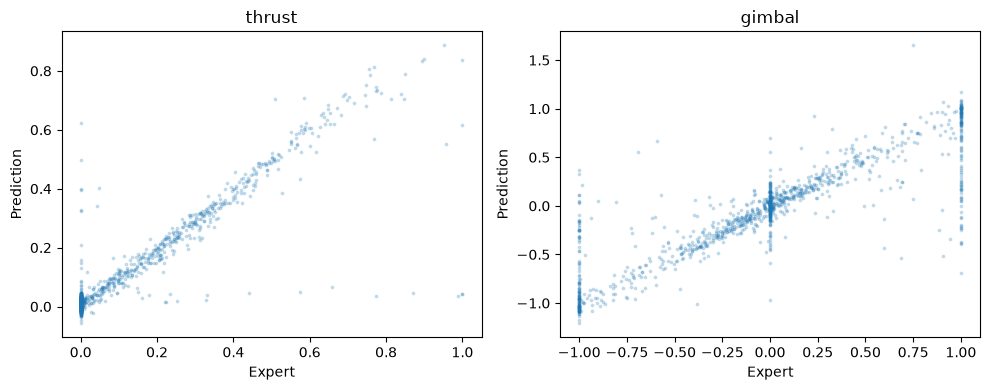

In [13]:
from model import create_model as create_base_model

tuned_model, tuning_results, tuning_histories = tune_model(
    model_factory=create_base_model,
    train_x=train_x, train_y=train_y, val_x=val_x, val_y=val_y,
    optimiser_class=optimiser, loss_fn=loss_fn,
    learning_rates=learning_rates, batch_sizes=batch_sizes,
    max_epochs=max_epochs, early_stopping_patience=early_stopping_patience,
    model_name="BaseModel",
)
print("Tuning results:")
display(tuning_results.head(5))
evaluate_model(tuned_model, test_x, test_y)

#### Interpretation

Batch size of 256 is quite slow compared to the others. As the model is very small, most of the time is spent on launching GPU operations, and there is no worry with memory overflow if we increase this. It also looks like the best loss is with a LR of 0.01 and batch size of 1024 with 2028 close behind which is good as training should be fast. For future models, I'll remove the batch size of 256 and 512 and increase the number of epochs so the larger batch sizes converge with a smaller learning rate.

#### Fixing the model output so it runs in the sim

Currently, the output unbounded, as you can see from the above plot which is an issue for the simulator. It only accepts outputs in the specified ranges so it errors with the model I gave you.

A simple fix is to add a sigmoid output to the thrust and a tanh activation to the gimbal output.
- torch.tanh()
- torch.sigmoid()

I don't expect this to really give a better result for the loss but it means it can be run in the simulator now.

In [14]:
batch_sizes = [1024, 2048, 4096] # Also adding a larger batch size to see if it helps with the training speed and stability.
max_epochs = 1000

ModelWithFixedActivations:   7%|▋         | 1/15 [00:48<11:13, 48.11s/run, best=0.02134]

ModelWithFixedActivations | lr 0.0001, batch size 1024 | best validation loss 0.02134 at epoch 394 (ran 404)


ModelWithFixedActivations:  13%|█▎        | 2/15 [01:27<09:21, 43.20s/run, best=0.02134]

ModelWithFixedActivations | lr 0.0001, batch size 2048 | best validation loss 0.02158 at epoch 567 (ran 577)


ModelWithFixedActivations:  20%|██        | 3/15 [02:08<08:22, 41.85s/run, best=0.02134]

ModelWithFixedActivations | lr 0.0001, batch size 4096 | best validation loss 0.02195 at epoch 884 (ran 894)


... (22 outputs left out)

ModelWithFixedActivations: 100%|██████████| 15/15 [04:17<00:00, 17.13s/run, best=0.01860]

ModelWithFixedActivations | lr 0.01, batch size 4096 | best validation loss 0.01904 at epoch 54 (ran 64)


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,ModelWithFixedActivations,0.010,1024,0.018599,44,54
1,ModelWithFixedActivations,0.010,2048,0.018604,52,62
2,ModelWithFixedActivations,0.005,1024,0.018793,54,64
3,ModelWithFixedActivations,0.010,4096,0.019036,54,64
4,ModelWithFixedActivations,0.001,4096,0.019122,287,297


thrust test MAE: 0.0253
gimbal test MAE: 0.1529


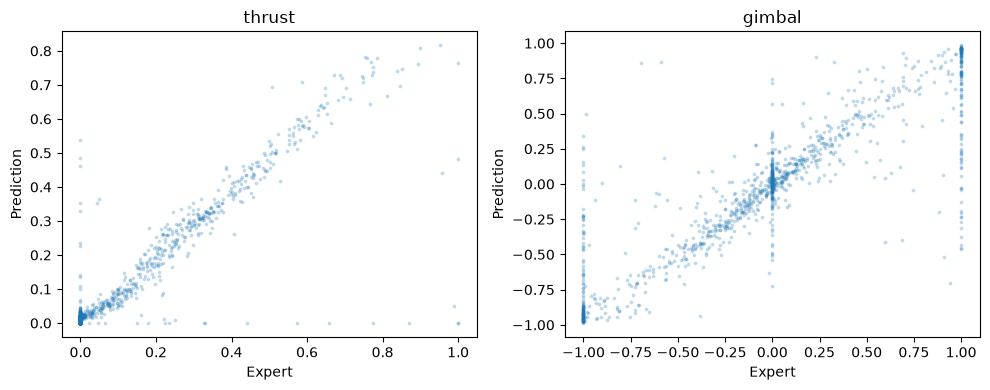

In [15]:
from fixone import create_model as create_fixed_one_model

tuned_model_fixed_activation, tuning_results, tuning_histories = tune_model(
    model_factory=create_fixed_one_model,
    train_x=train_x, train_y=train_y, val_x=val_x, val_y=val_y,
    optimiser_class=optimiser, loss_fn=loss_fn,
    learning_rates=learning_rates, batch_sizes=batch_sizes,
    max_epochs=max_epochs, early_stopping_patience=early_stopping_patience,
    model_name="ModelWithFixedActivations",
)
display(tuning_results.head(5))
evaluate_model(tuned_model_fixed_activation, test_x, test_y)

#### Intepretation

The thrust error is a bit better here, but the gimbal error is a bit worse. Now we have the bounded outputs though. The higher learning rates are definitely better for a simple model like this and the larger batch size too so we can keep them as they are.

Let's test in the sim.

Flights: 50
Mean score: 1.25 / 100
Landing success: 1/50 (2.0%)


,Flights
Failure reason,
vertical velocity outside limits,34
horizontal velocity outside limits,21
angular velocity outside limits,19
no contact,15
tilt outside limits,12
foot outside concrete pad,10
contact outside concrete pad,2


,Seed,Start x (m),Start height (m),Score / 100,Touchdown error,Simulation time (s),Landing feedback
0,78,-6.49,807.57,62.27,0.41,20.49,Safe landing
10,75,-22.94,426.56,0.00,0.58,11.02,vertical velocity outside limits
20,66,33.90,696.41,0.00,0.84,14.07,vertical velocity outside limits; horizontal v...
29,57,14.73,584.16,0.00,1.00,11.69,foot outside concrete pad; vertical velocity o...
39,59,7.02,763.03,0.00,inf,30.00,no contact
49,89,6.06,734.97,0.00,inf,30.00,no contact


Final state. Safe landing limits: |vx| <= 1.5 m/s, -3.0 <= vy <= 0 m/s, |tilt| <= 4.0 deg, |angular rate| <= 2.0 deg/s


,Seed,Final x (m),Final height (m),vx (m/s),vy (m/s),Tilt (deg),Angular rate (deg/s),Fuel left (kg)
0,78,-7.35,18.96,1.28,-2.78,-0.04,0.10,8353.41
10,75,-2.31,18.76,1.35,-4.77,1.54,-1.10,9595.03
20,66,-9.87,19.71,-11.34,-24.48,8.72,-9.39,9475.06
29,57,-32.85,19.20,-13.65,-24.10,-5.24,-12.66,9781.81
39,59,14.71,264.75,1.57,42.07,-0.38,-0.12,6571.12
49,89,11.86,287.81,1.50,44.44,-0.39,-0.02,6538.66


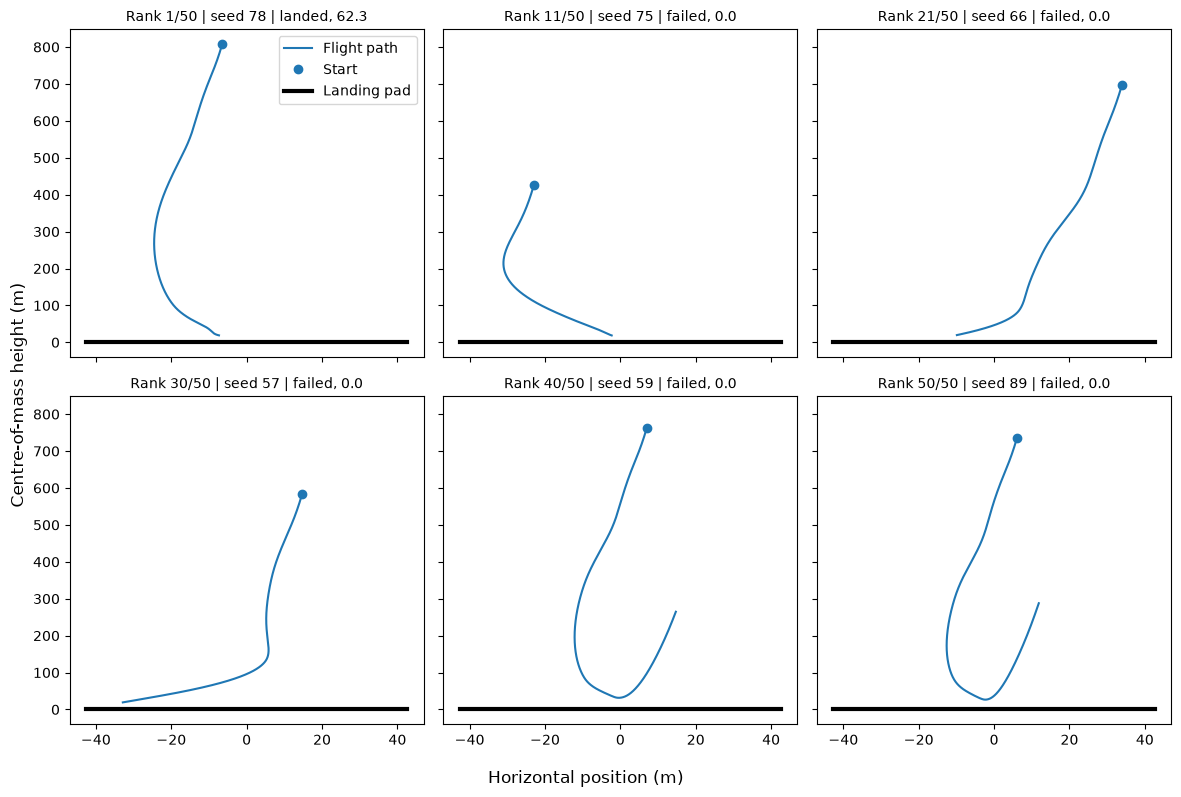

In [16]:
_ = run_sims(tuned_model_fixed_activation, name="Sigmoid/tanh outputs", step="1.1")

#### Interpretation

Quite a few of these fly off instead of crashing or landing. I think it is because the simulator needs an exact value of 0.0 in order to switch off the engine. 
A better loss function in that case will likely be some sort of clamped output but done in a way that it doesn't influence the gradients.

Something like `clamped = torch.clamp(x, 0, 1)`. However this isn't ideal because it is flat outside of this range and therefore it has no gradient. So instead of just this I'll add a line like this:

`return x + (clamped - x).detach()`

This means in the forward pass it returns clamped, but in the backwards pass the bracket is nothing and therefore the gradient is just x. Obviously this isn't ideal because it's approximate but it allows the model to return 0 now.

There is also an alternative to add a 3rd output or a feature that chooses to switch the engine on or off. I will test both. First the clamping.

ModelWithClampedThrustActivation:   7%|▋         | 1/15 [01:02<14:33, 62.41s/run, best=0.02065]

ModelWithClampedThrustActivation | lr 0.0001, batch size 1024 | best validation loss 0.02065 at epoch 497 (ran 507)


ModelWithClampedThrustActivation:  13%|█▎        | 2/15 [01:39<10:15, 47.38s/run, best=0.02065]

ModelWithClampedThrustActivation | lr 0.0001, batch size 2048 | best validation loss 0.02143 at epoch 518 (ran 528)


ModelWithClampedThrustActivation:  20%|██        | 3/15 [02:18<08:41, 43.46s/run, best=0.02065]

ModelWithClampedThrustActivation | lr 0.0001, batch size 4096 | best validation loss 0.02129 at epoch 882 (ran 892)


... (22 outputs left out)

ModelWithClampedThrustActivation: 100%|██████████| 15/15 [04:57<00:00, 19.85s/run, best=0.01751]

ModelWithClampedThrustActivation | lr 0.01, batch size 4096 | best validation loss 0.01751 at epoch 82 (ran 92)


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,ModelWithClampedThrustActivation,0.010,4096,0.017509,82,92
1,ModelWithClampedThrustActivation,0.010,1024,0.017828,43,53
2,ModelWithClampedThrustActivation,0.005,2048,0.018000,82,92
3,ModelWithClampedThrustActivation,0.005,4096,0.018278,68,78
4,ModelWithClampedThrustActivation,0.010,2048,0.018301,54,64


thrust test MAE: 0.0278
gimbal test MAE: 0.1506


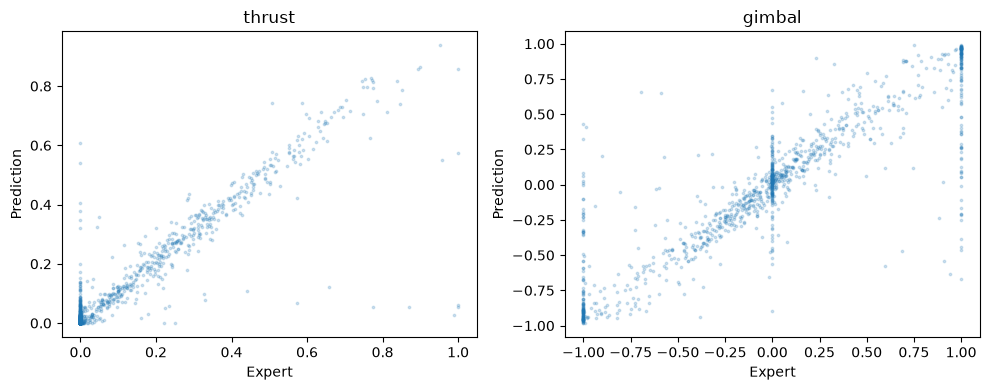

Flights: 50
Mean score: 2.71 / 100
Landing success: 2/50 (4.0%)


,Flights
Failure reason,
no contact,35
vertical velocity outside limits,12
angular velocity outside limits,10
contact outside concrete pad,9
foot outside concrete pad,9
horizontal velocity outside limits,5
tilt outside limits,1


,Seed,Start x (m),Start height (m),Score / 100,Touchdown error,Simulation time (s),Landing feedback
0,71,-19.73,613.77,69.75,0.51,14.08,Safe landing
10,90,-10.21,690.95,0.00,0.92,13.34,contact outside concrete pad; foot outside con...
20,47,19.34,726.83,0.00,inf,30.00,no contact
29,60,-14.06,363.57,0.00,inf,30.00,no contact
39,76,24.51,842.76,0.00,inf,30.00,no contact
49,89,6.06,734.97,0.00,inf,30.00,no contact


Final state. Safe landing limits: |vx| <= 1.5 m/s, -3.0 <= vy <= 0 m/s, |tilt| <= 4.0 deg, |angular rate| <= 2.0 deg/s


,Seed,Final x (m),Final height (m),vx (m/s),vy (m/s),Tilt (deg),Angular rate (deg/s),Fuel left (kg)
0,71,18.53,18.71,1.40,-1.45,-0.24,1.05,9167.76
10,90,35.70,19.12,0.94,-24.17,-4.10,-6.03,9598.09
20,47,45.33,26.74,1.10,0.79,-0.32,-0.01,7108.59
29,60,88.66,41.45,4.44,1.82,-1.13,-0.00,7052.55
39,76,62.42,29.58,2.07,0.59,-0.59,-0.02,7124.80
49,89,42.04,26.57,1.38,0.57,-0.37,-0.01,7113.85


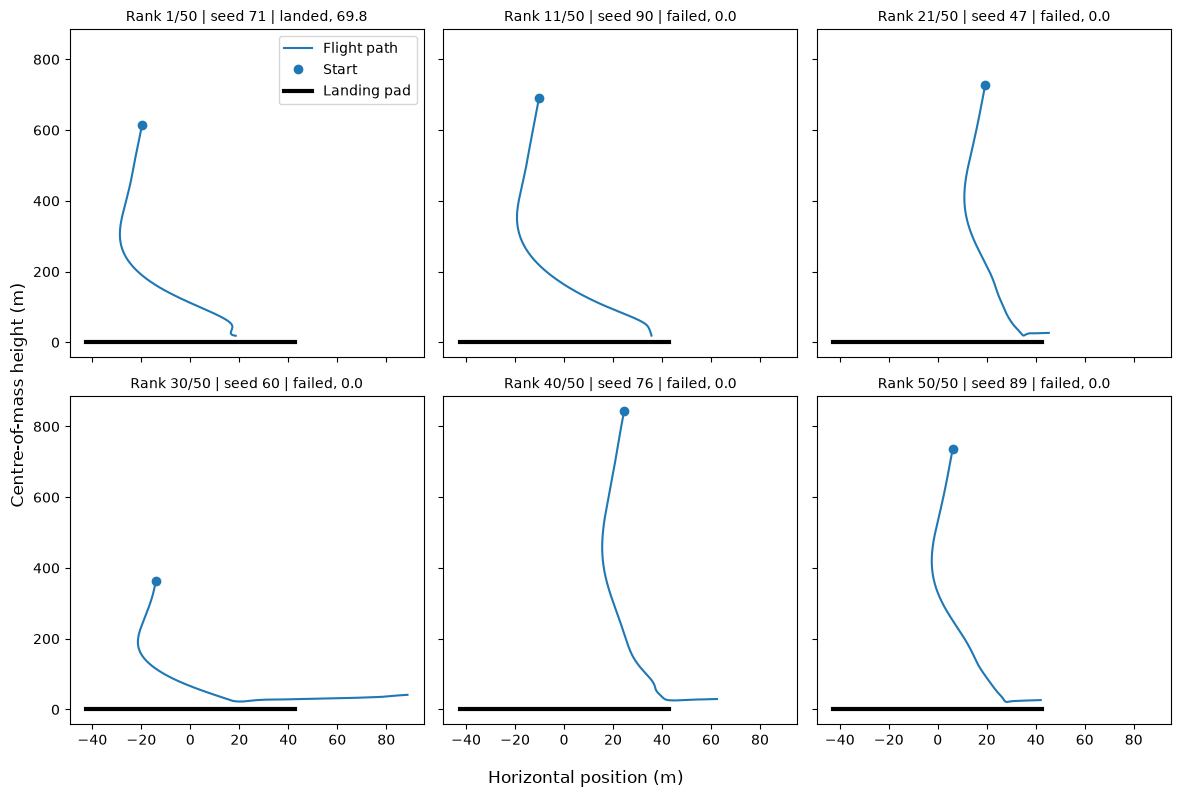

In [17]:
from clamped import create_model as create_clamped_model

tuned_model_clamped, tuning_results, tuning_histories = tune_model(
    model_factory=create_clamped_model,
    train_x=train_x, train_y=train_y, val_x=val_x, val_y=val_y,
    optimiser_class=optimiser, loss_fn=loss_fn,
    learning_rates=learning_rates, batch_sizes=batch_sizes,
    max_epochs=max_epochs, early_stopping_patience=early_stopping_patience,
    model_name="ModelWithClampedThrustActivation",
)
display(tuning_results.head(5))
evaluate_model(tuned_model_clamped, test_x, test_y)
_ = run_sims(tuned_model_clamped, name="Clamped thrust", step="1.2")

Well that's a win, two landings successful (one before), although a lot more of them hover without ever touching down now. Lets see if the thrust toggle is successful or not. One thing that is interesting is if the toggle is added is we can also adjust the loss to have a classification aspect - more on that later.

ModelWithThrustToggleActivation:   7%|▋         | 1/15 [00:07<01:45,  7.51s/run, best=0.03904]

ModelWithThrustToggleActivation | lr 0.0001, batch size 1024 | best validation loss 0.03904 at epoch 35 (ran 45)


ModelWithThrustToggleActivation:  13%|█▎        | 2/15 [00:13<01:28,  6.80s/run, best=0.03903]

ModelWithThrustToggleActivation | lr 0.0001, batch size 2048 | best validation loss 0.03903 at epoch 59 (ran 69)


ModelWithThrustToggleActivation:  20%|██        | 3/15 [00:21<01:26,  7.17s/run, best=0.03903]

ModelWithThrustToggleActivation | lr 0.0001, batch size 4096 | best validation loss 0.03908 at epoch 122 (ran 132)


... (22 outputs left out)

ModelWithThrustToggleActivation: 100%|██████████| 15/15 [01:22<00:00,  5.51s/run, best=0.02389]

ModelWithThrustToggleActivation | lr 0.01, batch size 4096 | best validation loss 0.03204 at epoch 32 (ran 42)


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,ModelWithThrustToggleActivation,0.005,4096,0.023887,134,144
1,ModelWithThrustToggleActivation,0.005,2048,0.024577,94,104
2,ModelWithThrustToggleActivation,0.005,1024,0.026335,34,44
3,ModelWithThrustToggleActivation,0.001,1024,0.028936,67,77
4,ModelWithThrustToggleActivation,0.010,1024,0.029334,27,37


thrust test MAE: 0.0764
gimbal test MAE: 0.1539


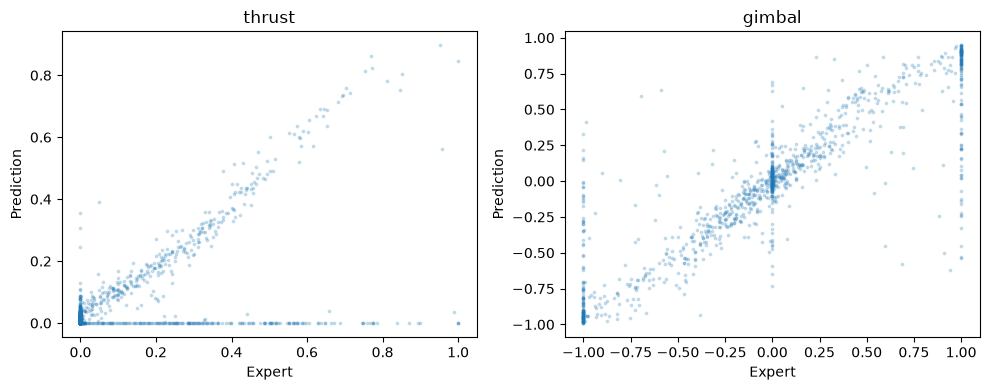

Flights: 50
Mean score: 0.00 / 100
Landing success: 0/50 (0.0%)


,Flights
Failure reason,
vertical velocity outside limits,50
tilt outside limits,46
horizontal velocity outside limits,45
angular velocity outside limits,31
foot outside concrete pad,1


,Seed,Start x (m),Start height (m),Score / 100,Touchdown error,Simulation time (s),Landing feedback
0,76,24.51,842.76,0.0,0.64,10.52,vertical velocity outside limits; horizontal v...
10,74,31.55,610.36,0.0,0.73,7.54,vertical velocity outside limits; horizontal v...
20,81,-5.27,455.81,0.0,0.85,9.94,vertical velocity outside limits; horizontal v...
29,87,5.66,741.77,0.0,0.91,10.36,vertical velocity outside limits; horizontal v...
39,48,-8.98,647.89,0.0,0.96,11.74,vertical velocity outside limits; horizontal v...
49,78,-6.49,807.57,0.0,1.00,11.38,foot outside concrete pad; vertical velocity o...


Final state. Safe landing limits: |vx| <= 1.5 m/s, -3.0 <= vy <= 0 m/s, |tilt| <= 4.0 deg, |angular rate| <= 2.0 deg/s


,Seed,Final x (m),Final height (m),vx (m/s),vy (m/s),Tilt (deg),Angular rate (deg/s),Fuel left (kg)
0,76,0.93,19.16,-2.29,-94.53,8.17,-0.16,11016.45
10,74,16.12,19.03,-2.01,-92.65,7.96,-0.18,11362.74
20,81,6.89,19.12,7.05,-31.32,5.41,5.19,10108.06
29,87,-15.30,19.75,8.32,-44.94,-11.80,9.39,10280.87
39,48,25.06,19.27,15.06,-28.72,5.99,11.62,9868.15
49,78,-30.97,19.92,8.03,-47.39,-13.52,8.13,10186.08


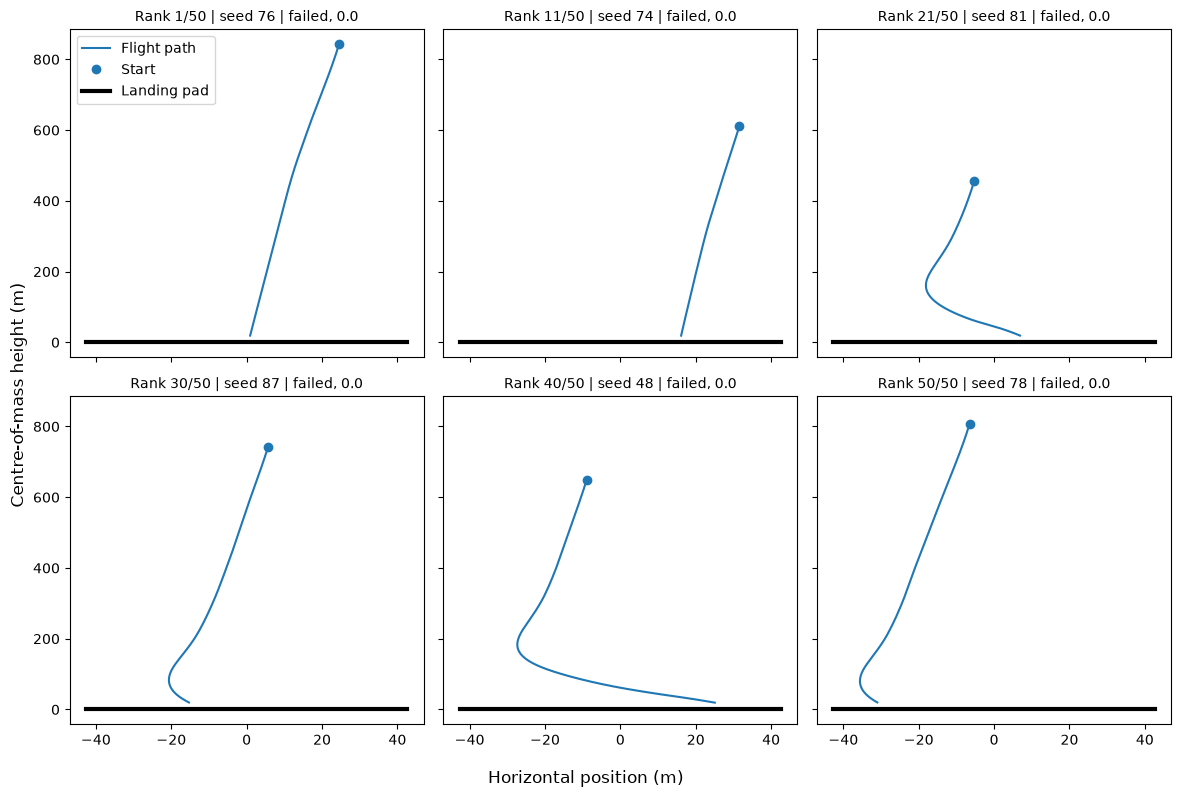

In [18]:
from thrust_toggle import create_model as create_thrust_toggle_model

tuned_model_thrust_toggle, tuning_results, tuning_histories = tune_model(
    model_factory=create_thrust_toggle_model,
    train_x=train_x, train_y=train_y, val_x=val_x, val_y=val_y,
    optimiser_class=optimiser, loss_fn=loss_fn,
    learning_rates=learning_rates, batch_sizes=batch_sizes,
    max_epochs=max_epochs, early_stopping_patience=early_stopping_patience,
    model_name="ModelWithThrustToggleActivation",
)
display(tuning_results.head(5))
evaluate_model(tuned_model_thrust_toggle, test_x, test_y)
_ = run_sims(tuned_model_thrust_toggle, name="Thrust toggle", step="1.3")

That's worse, no landings at all and they all come in far too fast, so the toggle on its own doesn't help. Now onto the classification objective in the loss function.

So at the moment I use a smooth L1 loss but with the throttle toggle I can also add a BCE loss to that component. In some sort of psuedo code it looks something like this:

```psuedocode
If y > 0 then throttle was on, assign this 1, otherwise 0.
and if prediction > 0 then assign the prediction to 1, otherwise 0
Penalise the difference between these with BCE.
Add this penalty to the original one.
```

In [19]:
def mixed_loss(model, x, y, alpha=0.08):
    model(x)
    on = (y[:, 0] > 0).float()
    gate_loss = nn.functional.binary_cross_entropy_with_logits(model.on_logit, on)
    throttle_loss = (nn.functional.smooth_l1_loss(model.throttle, y[:, 0], reduction="none") * on).sum() / on.sum().clamp_min(1.0)  # Avoid division by zero if no samples are on
    gimbal_loss = nn.functional.smooth_l1_loss(model.gimbal, y[:, 1])
    return alpha * gate_loss + throttle_loss + gimbal_loss

ModelWithThrustToggleActivationNewLoss:   7%|▋         | 1/15 [01:32<21:39, 92.85s/run, best=0.04962]

ModelWithThrustToggleActivationNewLoss | lr 0.0001, batch size 1024 | best validation loss 0.04962 at epoch 473 (ran 483)


ModelWithThrustToggleActivationNewLoss:  13%|█▎        | 2/15 [02:46<17:40, 81.56s/run, best=0.04962]

ModelWithThrustToggleActivationNewLoss | lr 0.0001, batch size 2048 | best validation loss 0.05028 at epoch 646 (ran 656)


ModelWithThrustToggleActivationNewLoss:  20%|██        | 3/15 [03:56<15:17, 76.48s/run, best=0.04962]

ModelWithThrustToggleActivationNewLoss | lr 0.0001, batch size 4096 | best validation loss 0.05069 at epoch 1000 (ran 1000)


... (22 outputs left out)

ModelWithThrustToggleActivationNewLoss: 100%|██████████| 15/15 [07:49<00:00, 31.31s/run, best=0.04190]

ModelWithThrustToggleActivationNewLoss | lr 0.01, batch size 4096 | best validation loss 0.04341 at epoch 61 (ran 71)


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,ModelWithThrustToggleActivationNewLoss,0.010,2048,0.041898,61,71
1,ModelWithThrustToggleActivationNewLoss,0.005,2048,0.043384,89,99
2,ModelWithThrustToggleActivationNewLoss,0.005,1024,0.043387,66,76
3,ModelWithThrustToggleActivationNewLoss,0.010,1024,0.043402,34,44
4,ModelWithThrustToggleActivationNewLoss,0.010,4096,0.043415,61,71


thrust test MAE: 0.0207
gimbal test MAE: 0.1506


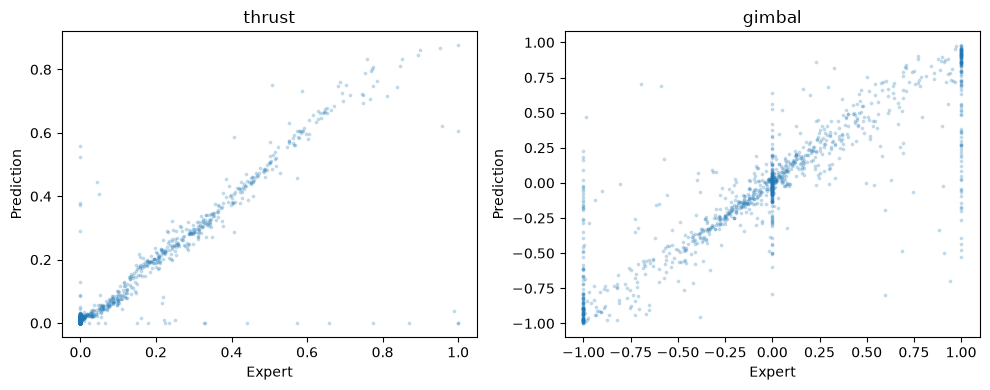

Flights: 50
Mean score: 0.00 / 100
Landing success: 0/50 (0.0%)


,Flights
Failure reason,
vertical velocity outside limits,33
horizontal velocity outside limits,33
angular velocity outside limits,26
foot outside concrete pad,15
no contact,14
contact outside concrete pad,11
tilt outside limits,10


,Seed,Start x (m),Start height (m),Score / 100,Touchdown error,Simulation time (s),Landing feedback
0,51,35.40,503.57,0.0,0.29,14.19,vertical velocity outside limits
10,67,-6.85,413.47,0.0,0.73,6.32,vertical velocity outside limits; horizontal v...
20,65,-36.21,609.11,0.0,0.84,7.90,vertical velocity outside limits; horizontal v...
29,74,31.55,610.36,0.0,0.99,7.86,foot outside concrete pad; vertical velocity o...
39,55,26.58,785.32,0.0,inf,30.00,no contact
49,89,6.06,734.97,0.0,inf,30.00,no contact


Final state. Safe landing limits: |vx| <= 1.5 m/s, -3.0 <= vy <= 0 m/s, |tilt| <= 4.0 deg, |angular rate| <= 2.0 deg/s


,Seed,Final x (m),Final height (m),vx (m/s),vy (m/s),Tilt (deg),Angular rate (deg/s),Fuel left (kg)
0,51,-2.76,18.69,-0.11,-5.58,0.19,-0.48,9204.56
10,67,2.73,18.49,9.39,-35.96,2.11,9.82,10669.59
20,65,-20.88,18.54,12.89,-44.72,2.32,14.06,10622.82
29,74,43.20,18.73,11.19,-48.80,3.85,15.84,10681.18
39,55,124.59,31.04,1.65,-1.34,0.71,-0.09,7157.72
49,89,122.73,31.07,1.71,-0.26,0.74,-0.10,7143.55


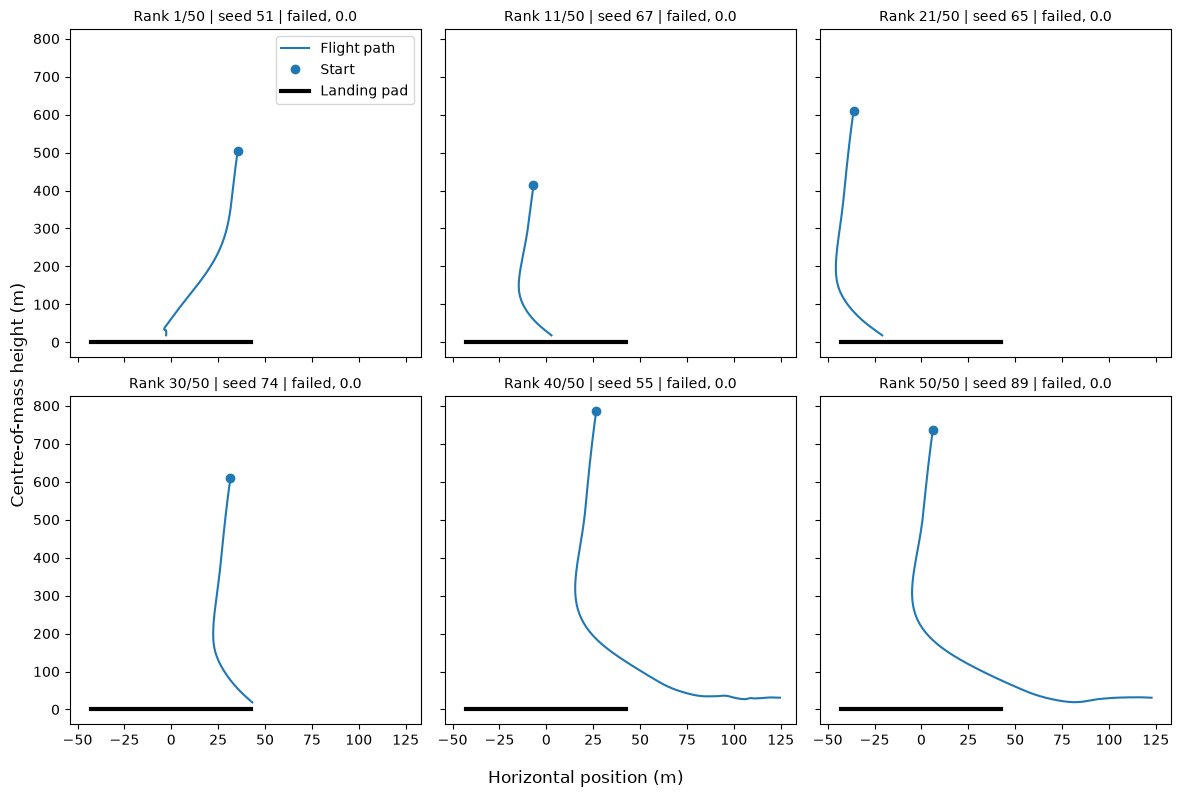

In [20]:
tuned_model_thrust_toggle_new_loss, tuning_results, tuning_histories = tune_model(
    model_factory=create_thrust_toggle_model,
    train_x=train_x, train_y=train_y, val_x=val_x, val_y=val_y,
    optimiser_class=optimiser, loss_fn=mixed_loss,
    learning_rates=learning_rates, batch_sizes=batch_sizes,
    max_epochs=max_epochs, early_stopping_patience=early_stopping_patience,
    model_name="ModelWithThrustToggleActivationNewLoss",
)
display(tuning_results.head(5))
evaluate_model(tuned_model_thrust_toggle_new_loss, test_x, test_y)
_ = run_sims(tuned_model_thrust_toggle_new_loss, name="Thrust toggle + gate loss", step="1.4")

#### Interpretation

Updating the loss function definitely improved the agreement (thrust MAE from 0.076 to 0.021), but it still didn't land any. As it's another thing to tune I will just use the clamped one going forward and then come back to it if that seems limited.

Next, I want to address the balance in the data. By binning the data I can sample uniformly from the bins, the idea is that 

In [21]:
# This divides the numerical range into bins and samples uniformly from each bin, so that the sampled data is more balanced across the range of the target variables.
def balanced_sample(frame, n_total, targets=TARGETS, n_bins=10, seed=0):
    """Sample rows evenly across a grid of bins, with one dimension per target.

    n_bins is the number of bins per target: one int for all targets, or a list with one per target.
    Returns exactly n_total rows. Cells with too few rows are oversampled, so rows can be duplicated.
    """
    if isinstance(n_bins, int):
        n_bins = [n_bins] * len(targets)
    rng = np.random.default_rng(seed)

    # Give every row a bin number for each target. Together these are its cell in the grid.
    grid = []
    for target, bins in zip(targets, n_bins, strict=True):
        codes = pd.cut(frame[target], bins=bins, labels=False)
        if target == "thrust":
            # Exactly 0 is engine off, but 0.00001 is on at minimum thrust, so off gets its own bin.
            codes = codes.mask(frame[target] == 0, -1)
        grid.append(codes.rename(f"{target}_bin"))

    # The row positions in each occupied cell. Empty cells have nothing to sample, so they are skipped.
    cells = list(frame.groupby(grid).indices.values())
    per_cell, remainder = divmod(n_total, len(cells))
    if per_cell == 0:
        raise ValueError(f"n_total must be at least {len(cells)}, the number of occupied cells.")

    # If n_total does not divide evenly, randomly chosen cells get one extra row each.
    sizes = np.full(len(cells), per_cell)
    sizes[rng.permutation(len(cells))[:remainder]] += 1

    # Rows are only repeated when a cell has fewer of them than it needs. Repeats are spread evenly:
    # every row is used size // len(rows) times, and a random selection of rows is used once more.
    chosen = []
    for rows, size in zip(cells, sizes):
        repeats, extra = divmod(size, len(rows))
        chosen.append(np.tile(rows, repeats))
        chosen.append(rng.choice(rows, size=extra, replace=False))

    # Shuffle because the cells should not be in any particular order.
    return frame.iloc[rng.permutation(np.concatenate(chosen))]

# Only the training data is balanced, so that validation and test still match real flights.
balanced_train = balanced_sample(train, n_total=80_000)
balanced_x, balanced_y = tensors(balanced_train)

ModelClampedWithBalancedTrainingData:   7%|▋         | 1/15 [00:09<02:19,  9.94s/run, best=0.04631]

ModelClampedWithBalancedTrainingData | lr 0.0001, batch size 1024 | best validation loss 0.04631 at epoch 56 (ran 66)


ModelClampedWithBalancedTrainingData:  13%|█▎        | 2/15 [00:20<02:13, 10.26s/run, best=0.04612]

ModelClampedWithBalancedTrainingData | lr 0.0001, batch size 2048 | best validation loss 0.04612 at epoch 113 (ran 123)


ModelClampedWithBalancedTrainingData:  20%|██        | 3/15 [00:31<02:09, 10.79s/run, best=0.04612]

ModelClampedWithBalancedTrainingData | lr 0.0001, batch size 4096 | best validation loss 0.04654 at epoch 196 (ran 206)


... (22 outputs left out)

ModelClampedWithBalancedTrainingData: 100%|██████████| 15/15 [01:54<00:00,  7.64s/run, best=0.02963]

ModelClampedWithBalancedTrainingData | lr 0.01, batch size 4096 | best validation loss 0.03516 at epoch 36 (ran 46)


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,ModelClampedWithBalancedTrainingData,0.0100,1024,0.029627,68,78
1,ModelClampedWithBalancedTrainingData,0.0100,4096,0.035160,36,46
2,ModelClampedWithBalancedTrainingData,0.0050,2048,0.036923,43,53
3,ModelClampedWithBalancedTrainingData,0.0005,1024,0.037695,83,93
4,ModelClampedWithBalancedTrainingData,0.0050,1024,0.037768,22,32


thrust test MAE: 0.0673
gimbal test MAE: 0.2227


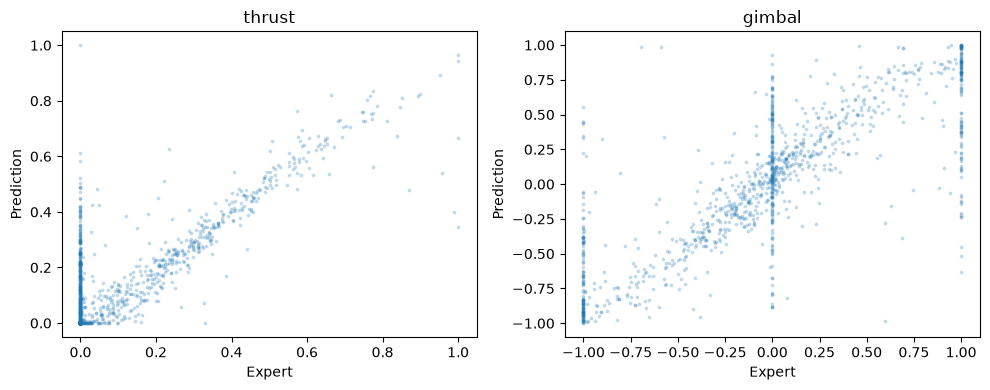

Flights: 50
Mean score: 0.00 / 100
Landing success: 0/50 (0.0%)


,Flights
Failure reason,
vertical velocity outside limits,31
horizontal velocity outside limits,31
tilt outside limits,31
angular velocity outside limits,31
foot outside concrete pad,20
no contact,19
contact outside concrete pad,14


,Seed,Start x (m),Start height (m),Score / 100,Touchdown error,Simulation time (s),Landing feedback
0,51,35.40,503.57,0.0,0.81,13.52,vertical velocity outside limits; horizontal v...
10,42,21.92,569.44,0.0,1.00,15.11,vertical velocity outside limits; horizontal v...
20,68,-1.25,774.16,0.0,1.00,12.80,foot outside concrete pad; vertical velocity o...
29,90,-10.21,690.95,0.0,1.00,11.50,contact outside concrete pad; foot outside con...
39,60,-14.06,363.57,0.0,inf,30.00,no contact
49,89,6.06,734.97,0.0,inf,30.00,no contact


Final state. Safe landing limits: |vx| <= 1.5 m/s, -3.0 <= vy <= 0 m/s, |tilt| <= 4.0 deg, |angular rate| <= 2.0 deg/s


,Seed,Final x (m),Final height (m),vx (m/s),vy (m/s),Tilt (deg),Angular rate (deg/s),Fuel left (kg)
0,51,-3.17,20.23,11.66,-23.99,14.58,15.49,9462.21
10,42,23.25,19.85,10.49,-27.29,42.29,17.28,9233.06
20,68,36.91,20.15,-11.43,-14.49,13.70,-12.47,9509.04
29,90,42.25,20.55,-9.18,-19.08,27.50,-8.26,9706.26
39,60,156.03,102.39,4.95,3.68,0.13,-1.95,6984.17
49,89,104.37,77.17,3.06,6.43,-0.09,-0.50,7036.59


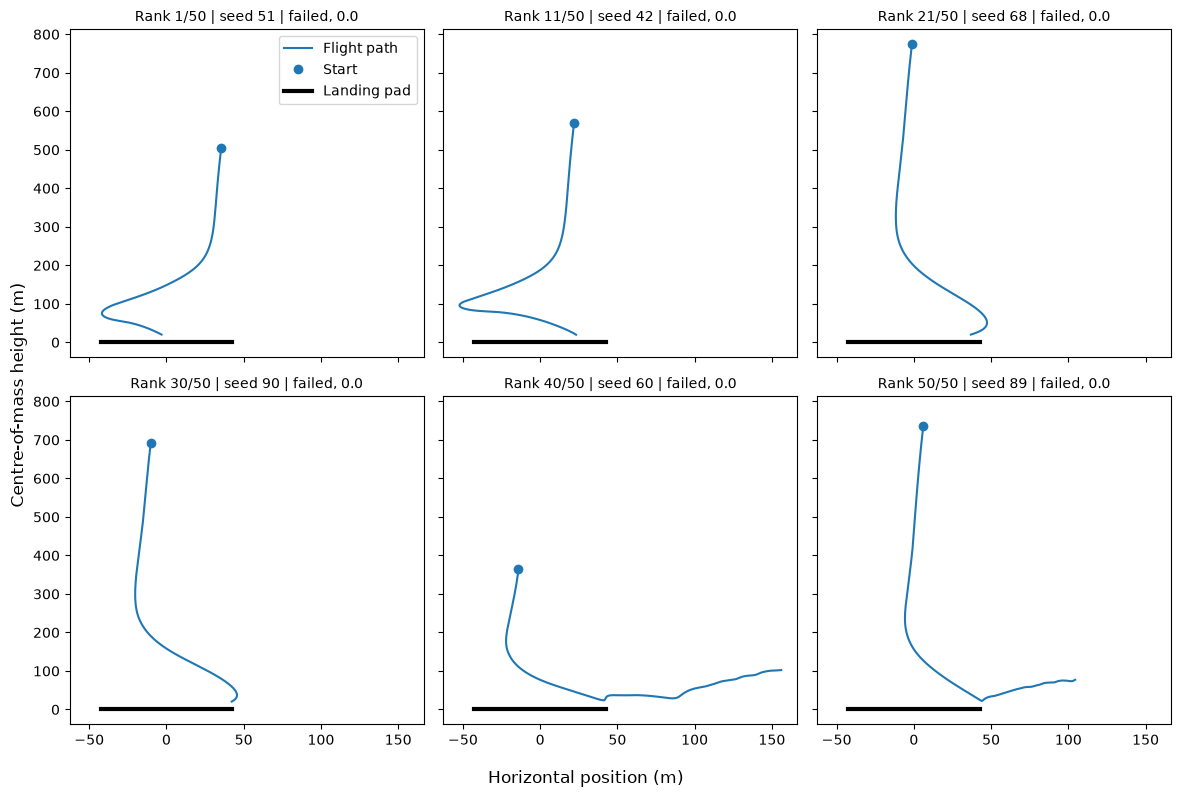

In [22]:
tuned_model_balanced, tuning_results, tuning_histories = tune_model(
    model_factory=create_clamped_model,
    train_x=balanced_x, train_y=balanced_y, val_x=val_x, val_y=val_y,
    optimiser_class=optimiser, loss_fn=loss_fn,
    learning_rates=learning_rates, batch_sizes=batch_sizes,
    max_epochs=max_epochs, early_stopping_patience=early_stopping_patience,
    model_name="ModelClampedWithBalancedTrainingData",
)
display(tuning_results.head(5))
evaluate_model(tuned_model_balanced, test_x, test_y)
_ = run_sims(tuned_model_balanced, name="Clamped + balanced data", step="1.5")

#### Interpretation

Not good so I will scrap that for now. There is probably some configuration that is better but for now I will go to improving the model and not the data quality.

The next thing I think I shall test is with the previous thrust and gimbal. I believe that the model is maybe just learning the relationship between the current thrust and previous one so I will remove that from the features and see. Again with both the clamped and the thrust feature.

ModelPastActuatorsRemoved:   7%|▋         | 1/15 [00:59<13:57, 59.84s/run, best=0.03506]

ModelPastActuatorsRemoved | lr 0.0001, batch size 1024 | best validation loss 0.03506 at epoch 381 (ran 391)


ModelPastActuatorsRemoved:  13%|█▎        | 2/15 [01:46<11:20, 52.32s/run, best=0.03506]

ModelPastActuatorsRemoved | lr 0.0001, batch size 2048 | best validation loss 0.03532 at epoch 526 (ran 536)


ModelPastActuatorsRemoved:  20%|██        | 3/15 [02:39<10:26, 52.24s/run, best=0.03480]

ModelPastActuatorsRemoved | lr 0.0001, batch size 4096 | best validation loss 0.03480 at epoch 902 (ran 912)


... (22 outputs left out)

ModelPastActuatorsRemoved: 100%|██████████| 15/15 [05:52<00:00, 23.50s/run, best=0.02980]

ModelPastActuatorsRemoved | lr 0.01, batch size 4096 | best validation loss 0.02980 at epoch 110 (ran 120)


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,ModelPastActuatorsRemoved,0.01,4096,0.029797,110,120
1,ModelPastActuatorsRemoved,0.01,2048,0.029967,43,53


thrust test MAE: 0.0564
gimbal test MAE: 0.2452


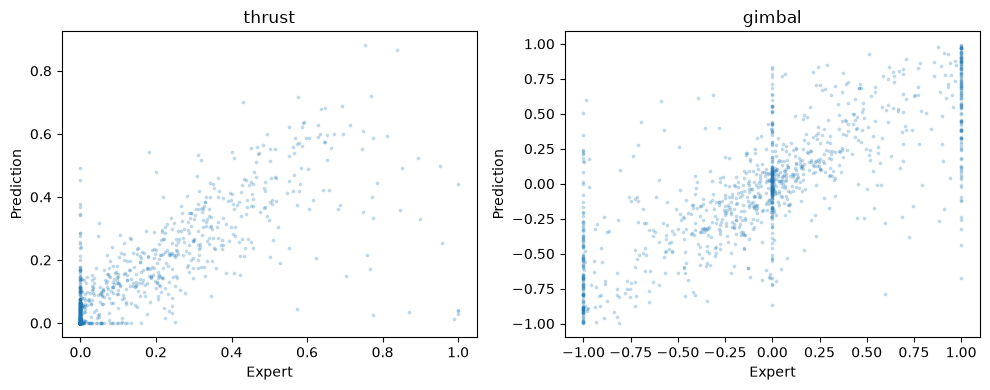

Flights: 50
Mean score: 15.14 / 100
Landing success: 9/50 (18.0%)


,Flights
Failure reason,
vertical velocity outside limits,39
angular velocity outside limits,23
tilt outside limits,11
horizontal velocity outside limits,4
foot outside concrete pad,1


,Seed,Start x (m),Start height (m),Score / 100,Touchdown error,Simulation time (s),Landing feedback
0,86,9.24,437.68,98.77,0.06,13.74,Safe landing
10,62,8.75,723.89,0.00,0.25,14.71,vertical velocity outside limits
20,80,18.92,359.21,0.00,0.59,10.47,angular velocity outside limits
29,83,-14.69,372.30,0.00,0.66,10.47,vertical velocity outside limits; angular velo...
39,49,-10.97,646.61,0.00,0.75,13.75,vertical velocity outside limits
49,53,-39.11,709.46,0.00,1.00,14.94,foot outside concrete pad; vertical velocity o...


Final state. Safe landing limits: |vx| <= 1.5 m/s, -3.0 <= vy <= 0 m/s, |tilt| <= 4.0 deg, |angular rate| <= 2.0 deg/s


,Seed,Final x (m),Final height (m),vx (m/s),vy (m/s),Tilt (deg),Angular rate (deg/s),Fuel left (kg)
0,86,-2.37,18.67,0.05,-0.58,0.03,-0.01,9181.19
10,62,4.99,18.71,-0.02,-3.54,-0.18,0.11,9125.23
20,80,-8.76,18.78,-0.33,-2.94,-1.83,2.40,9643.15
29,83,-0.23,19.01,0.61,-4.56,3.47,-2.65,9659.68
39,49,13.16,19.18,0.99,-6.05,3.77,-1.47,9278.93
49,53,33.52,20.03,2.19,-7.95,10.86,-3.06,9175.71


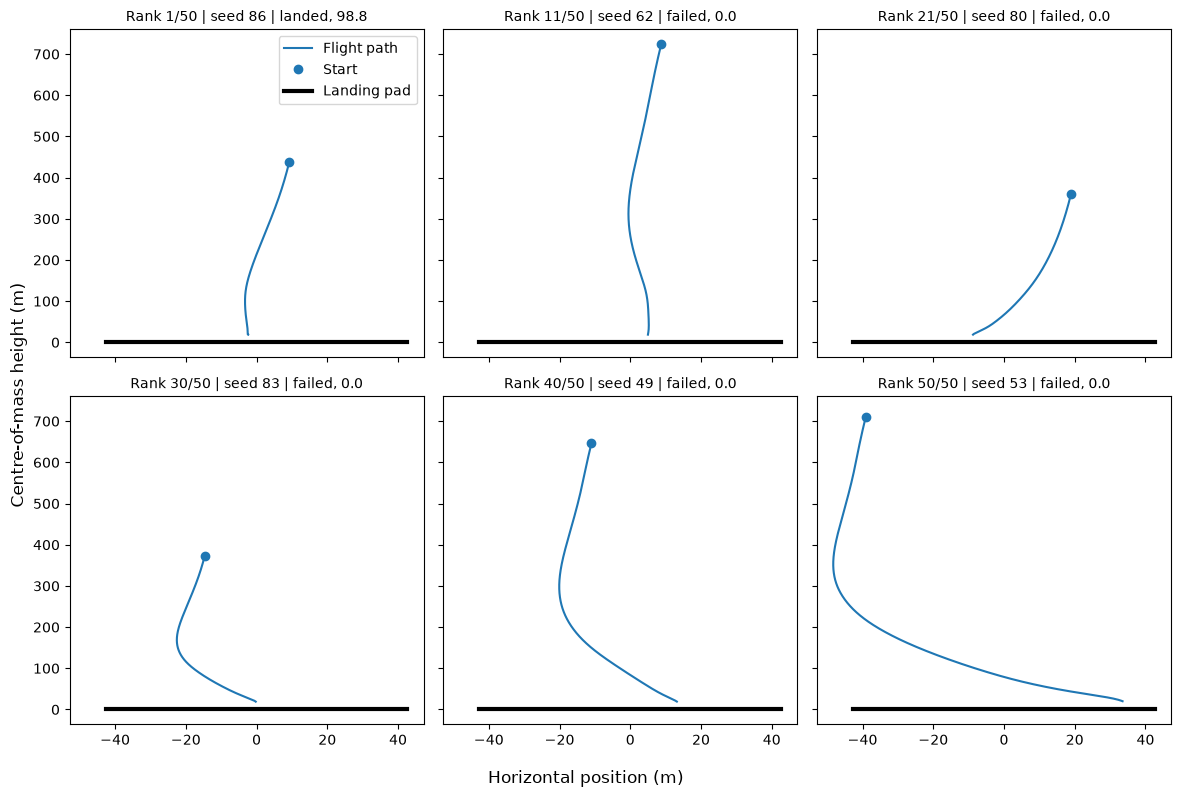

In [23]:
from remove_past_features import create_model as create_remove_past_features_model

tuned_model_past_removed, tuning_results, tuning_histories = tune_model(
    model_factory=create_remove_past_features_model,
    train_x=train_x, train_y=train_y, val_x=val_x, val_y=val_y,
    optimiser_class=optimiser, loss_fn=loss_fn,
    learning_rates=learning_rates, batch_sizes=batch_sizes,
    max_epochs=max_epochs, early_stopping_patience=early_stopping_patience,
    model_name="ModelPastActuatorsRemoved",
)
display(tuning_results.head(2))
evaluate_model(tuned_model_past_removed, test_x, test_y)
_ = run_sims(tuned_model_past_removed, name="Past actuators removed", step="1.6")

#### Interpretation

This is significantly better on the landing, but worse on the agreement. Next step is to just try to add another layer to increase the model complexity, but I believe this might just better the agreement and not the landing performance.

ModelExtraLayerAndDropout:   7%|▋         | 1/15 [01:25<19:54, 85.31s/run, best=0.03052]

ModelExtraLayerAndDropout | lr 0.0001, batch size 1024 | best validation loss 0.03052 at epoch 340 (ran 350)


ModelExtraLayerAndDropout:  13%|█▎        | 2/15 [02:39<17:00, 78.52s/run, best=0.03052]

ModelExtraLayerAndDropout | lr 0.0001, batch size 2048 | best validation loss 0.03066 at epoch 441 (ran 451)


ModelExtraLayerAndDropout:  20%|██        | 3/15 [04:15<17:19, 86.66s/run, best=0.02990]

ModelExtraLayerAndDropout | lr 0.0001, batch size 4096 | best validation loss 0.02990 at epoch 782 (ran 792)


... (22 outputs left out)

ModelExtraLayerAndDropout: 100%|██████████| 15/15 [08:14<00:00, 32.98s/run, best=0.02713]

ModelExtraLayerAndDropout | lr 0.01, batch size 4096 | best validation loss 0.02826 at epoch 46 (ran 56)


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,ModelExtraLayerAndDropout,0.001,2048,0.027129,181,191
1,ModelExtraLayerAndDropout,0.010,2048,0.027323,61,71


thrust test MAE: 0.0597
gimbal test MAE: 0.2226


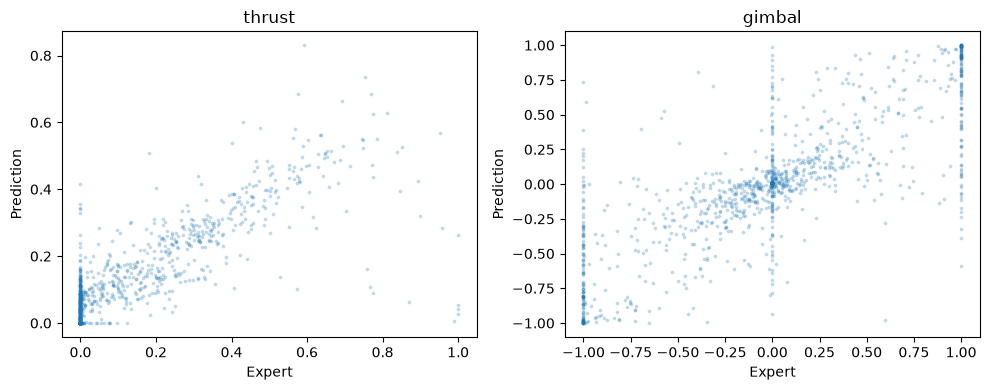

Flights: 50
Mean score: 1.36 / 100
Landing success: 1/50 (2.0%)


,Flights
Failure reason,
vertical velocity outside limits,49
horizontal velocity outside limits,27
tilt outside limits,8


,Seed,Start x (m),Start height (m),Score / 100,Touchdown error,Simulation time (s),Landing feedback
0,73,-0.59,501.68,67.83,0.48,13.08,Safe landing
10,63,4.81,846.13,0.00,0.37,15.41,vertical velocity outside limits
20,76,24.51,842.76,0.00,0.48,15.27,vertical velocity outside limits
29,74,31.55,610.36,0.00,0.61,13.15,vertical velocity outside limits; horizontal v...
39,83,-14.69,372.30,0.00,0.66,9.65,vertical velocity outside limits; horizontal v...
49,53,-39.11,709.46,0.00,0.81,15.88,vertical velocity outside limits; horizontal v...


Final state. Safe landing limits: |vx| <= 1.5 m/s, -3.0 <= vy <= 0 m/s, |tilt| <= 4.0 deg, |angular rate| <= 2.0 deg/s


,Seed,Final x (m),Final height (m),vx (m/s),vy (m/s),Tilt (deg),Angular rate (deg/s),Fuel left (kg)
0,73,3.18,18.82,0.71,-2.36,1.31,-1.45,9296.15
10,63,5.23,18.71,0.66,-8.20,0.16,0.41,9109.12
20,76,9.70,18.83,-1.21,-7.67,-0.94,-0.20,9118.33
29,74,6.69,18.78,-1.86,-6.67,-1.13,-1.16,9361.21
39,83,-2.26,18.83,2.64,-6.64,2.53,1.25,9798.80
49,53,14.65,19.99,4.61,-11.11,10.16,1.01,9079.56


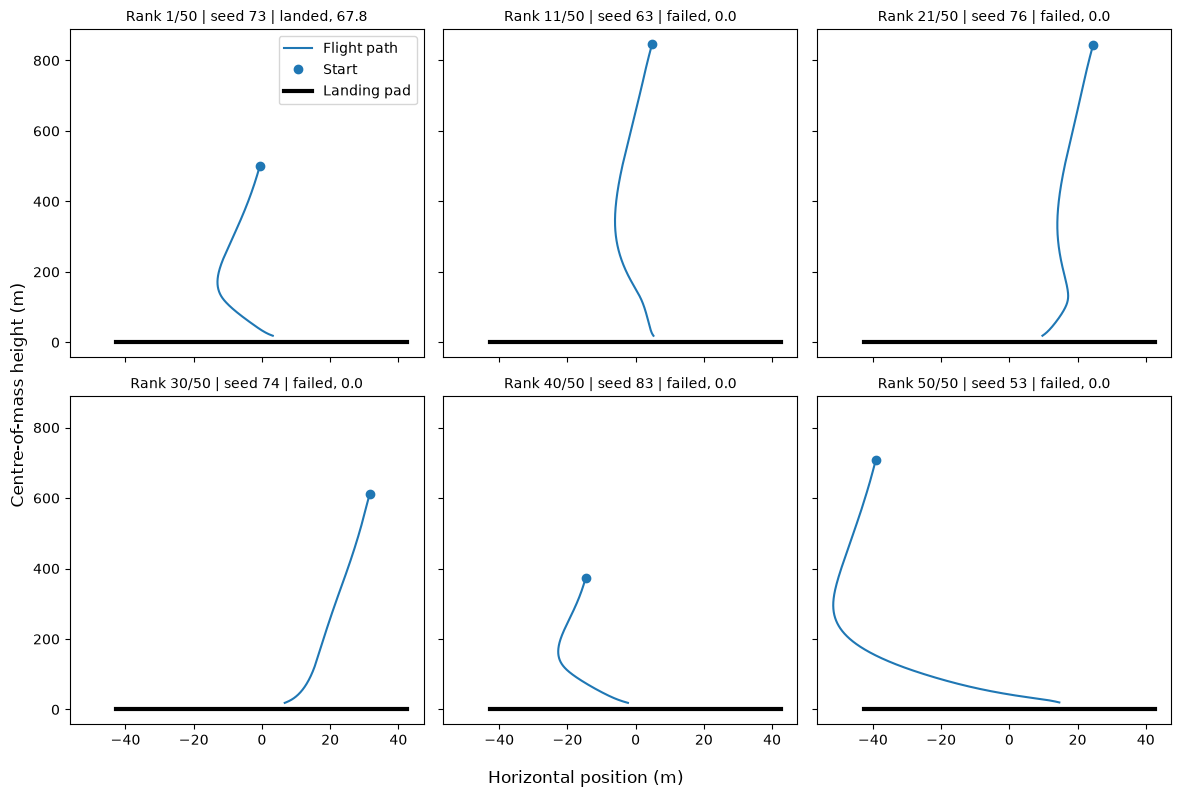

In [24]:
from layers_and_dropout import create_model as create_layers_and_dropout_model

tuned_model_layers, tuning_results, tuning_histories = tune_model(
    model_factory=create_layers_and_dropout_model,
    train_x=train_x, train_y=train_y, val_x=val_x, val_y=val_y,
    optimiser_class=optimiser, loss_fn=loss_fn,
    learning_rates=learning_rates, batch_sizes=batch_sizes,
    max_epochs=max_epochs, early_stopping_patience=early_stopping_patience,
    model_name="ModelExtraLayerAndDropout",
)
display(tuning_results.head(2))
evaluate_model(tuned_model_layers, test_x, test_y)
_ = run_sims(tuned_model_layers, name="Extra layer + dropout", step="1.7")

#### Interpretation

As expected the agreement is better but landing performance is worse. The plots look very similar though so I think it's potentially overfitting to the loss instead of the actual task. Reverting this change.

The next step is to create some more informative features, ideally we want to do this outside of the model, which I will do for training. Unfortunately for the online submission it will have to be done in the model so we don't benefit from the batching data but given that its a step by step simulation that's not really an issue.

ModelClampedWithAcceleration:   7%|▋         | 1/15 [01:43<24:06, 103.32s/run, best=0.03138]

ModelClampedWithAcceleration | lr 0.0001, batch size 1024 | best validation loss 0.03138 at epoch 659 (ran 669)


ModelClampedWithAcceleration:  13%|█▎        | 2/15 [02:52<18:05, 83.50s/run, best=0.03138] 

ModelClampedWithAcceleration | lr 0.0001, batch size 2048 | best validation loss 0.03227 at epoch 768 (ran 778)


ModelClampedWithAcceleration:  20%|██        | 3/15 [03:49<14:14, 71.20s/run, best=0.03138]

ModelClampedWithAcceleration | lr 0.0001, batch size 4096 | best validation loss 0.03276 at epoch 948 (ran 958)


... (22 outputs left out)

ModelClampedWithAcceleration: 100%|██████████| 15/15 [07:09<00:00, 28.66s/run, best=0.02773]

ModelClampedWithAcceleration | lr 0.01, batch size 4096 | best validation loss 0.02851 at epoch 62 (ran 72)


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,ModelClampedWithAcceleration,0.005,2048,0.027730,72,82
1,ModelClampedWithAcceleration,0.010,1024,0.027793,71,81


thrust test MAE: 0.0540
gimbal test MAE: 0.2350


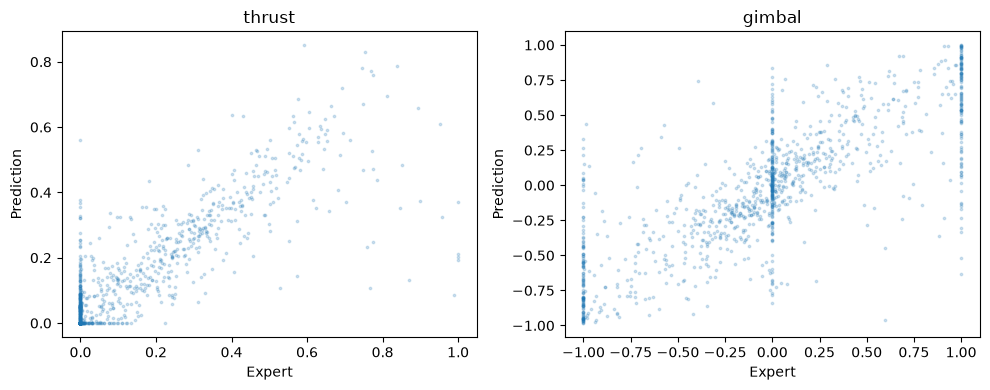

Flights: 50
Mean score: 48.51 / 100
Landing success: 27/50 (54.0%)


,Flights
Failure reason,
angular velocity outside limits,23
vertical velocity outside limits,4


,Seed,Start x (m),Start height (m),Score / 100,Touchdown error,Simulation time (s),Landing feedback
0,57,14.73,584.16,99.67,0.05,20.72,Safe landing
10,62,8.75,723.89,93.94,0.17,14.93,Safe landing
20,59,7.02,763.03,86.43,0.20,15.06,Safe landing
29,66,33.90,696.41,0.00,0.34,15.02,angular velocity outside limits
39,78,-6.49,807.57,0.00,0.50,15.62,angular velocity outside limits
49,53,-39.11,709.46,0.00,0.61,15.81,angular velocity outside limits


Final state. Safe landing limits: |vx| <= 1.5 m/s, -3.0 <= vy <= 0 m/s, |tilt| <= 4.0 deg, |angular rate| <= 2.0 deg/s


,Seed,Final x (m),Final height (m),vx (m/s),vy (m/s),Tilt (deg),Angular rate (deg/s),Fuel left (kg)
0,57,-2.32,18.98,-0.16,-0.15,0.03,-0.01,8282.46
10,62,2.90,18.71,0.31,-1.22,0.07,0.27,9065.55
20,59,3.73,18.71,0.32,-1.95,0.02,0.09,9063.62
29,66,-3.63,18.86,-0.29,-0.48,-0.98,2.14,9043.70
39,78,8.25,18.89,0.05,-2.86,1.12,-2.37,9009.90
49,53,14.84,19.08,0.09,-2.83,2.33,-4.15,8983.21


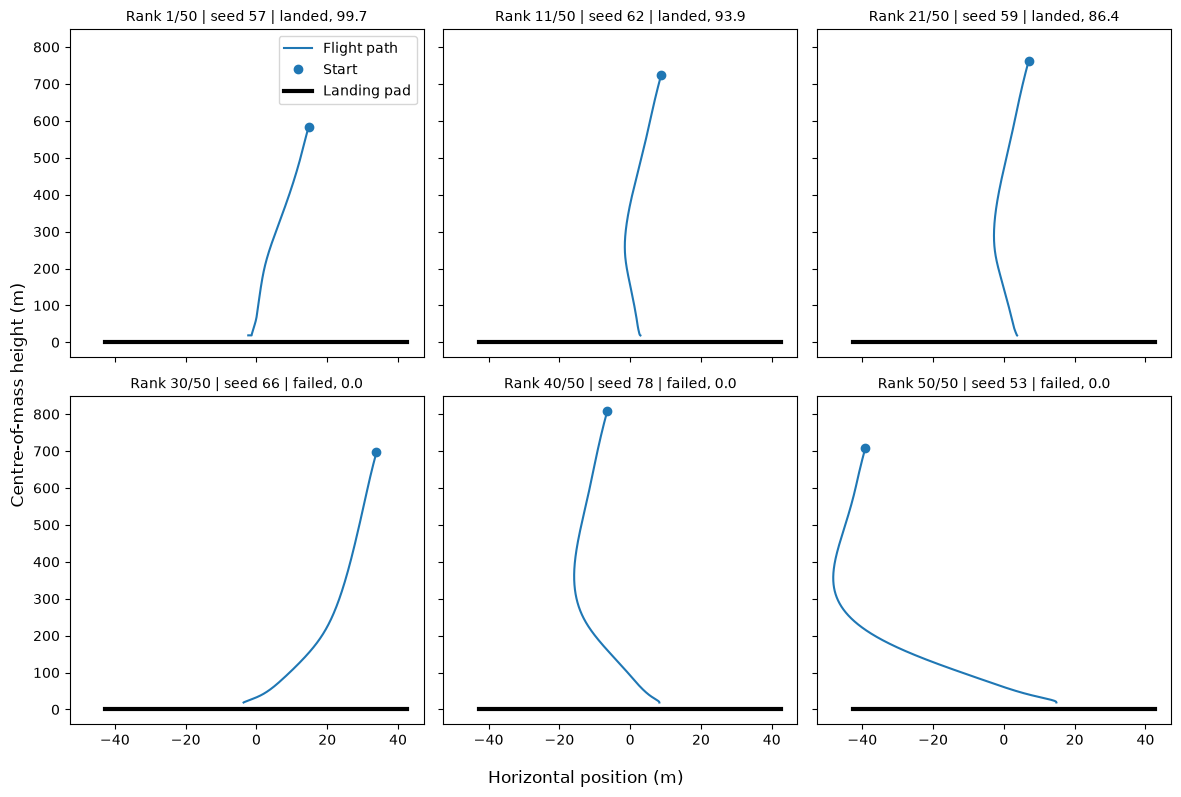

In [25]:
# The first feature I'm going to create is acceleration, for x, y and rotation. The simulator only gives the model the current observation,
# so instead of using the difference from the previous velocity, the model computes it from the forces using the simulator's equations.
# It then rolls the engine-off flight forward to the ground and predicts the landing (see acceleration_features.py).
from acceleration_features import create_model as create_acceleration_model

tuned_model_acceleration, tuning_results, tuning_histories = tune_model(
    model_factory=create_acceleration_model,
    train_x=train_x, train_y=train_y, val_x=val_x, val_y=val_y,
    optimiser_class=optimiser, loss_fn=loss_fn,
    learning_rates=learning_rates, batch_sizes=batch_sizes,
    max_epochs=max_epochs, early_stopping_patience=early_stopping_patience,
    model_name="ModelClampedWithAcceleration",
)
display(tuning_results.head(2))
evaluate_model(tuned_model_acceleration, test_x, test_y)
_ = run_sims(tuned_model_acceleration, name="Engine-off landing prediction", step="1.8")

# Part 2: Making the acceleration features fast

With the original training loop, the grid search for the acceleration model took far longer than anything else, and flying 50 flights was slow too. The features have no weights, so it was worth finding out where the time goes before trying anything else.

## Why is it slow?

I'm timing `features()` on its own, on the CPU, for one observation (what the simulator does) and for a batch of 2048 (what training does).

In [26]:
from torch.profiler import profile, ProfilerActivity

# I'm timing on the CPU so the numbers aren't hidden by the GPU running things in the background
cpu_model = create_acceleration_model().eval()
sample = train_x[:2048].cpu()

def time_it(fn, *args, repeats=100):
    """Average time for one call, in milliseconds. It runs once first so any first-call setup isn't counted."""
    with torch.inference_mode():
        fn(*args)
        start = time.perf_counter()
        for _ in range(repeats):
            fn(*args)
    return (time.perf_counter() - start) / repeats * 1000

print(f"features(), batch of 1:    {time_it(cpu_model.features, sample[:1]):.2f} ms")
print(f"features(), batch of 2048: {time_it(cpu_model.features, sample):.2f} ms")
print(f"layers only, batch of 1:   {time_it(cpu_model.layers, torch.zeros(1, 15)):.3f} ms")

# The profiler records every torch operation, so this counts how many separate operations one call actually runs
with torch.inference_mode(), profile(activities=[ProfilerActivity.CPU]) as prof:
    cpu_model.features(sample[:1])
print("Torch operations in one features() call:", sum(event.count for event in prof.key_averages() if event.key.startswith("aten::")))

features(), batch of 1:    6.31 ms
features(), batch of 2048: 7.59 ms
layers only, batch of 1:   0.072 ms
Torch operations in one features() call: 2677


#### Interpretation

On my machine `features()` took about 6.3 ms for one observation and 7.6 ms for 2048. The network itself took 0.07 ms, so the features cost about 90 times more than the network.

The important part is that 1 row and 2048 rows take nearly the same time. The maths isn't what's slow. One call runs about **2,700 separate small torch operations** (8 RK2 steps, each computing the drag, lift and torque twice), and each one has a fixed cost to launch. On a GPU it's even worse, because every operation is a separate kernel launch.

## Things I tried to make the function itself faster

1. Fewer RK2 steps. This should be roughly linear in time, but the prediction gets less accurate. I'm comparing each against a 64-step float64 reference.
2. `torch.jit.script`, which compiles the function and cuts out some Python overhead. It doesn't support functions defined inside other functions, so I rewrote the same maths as flat functions in `feature_experiments.py`.
3. `torch.compile`, which fuses operations together. It needs a C++ compiler on the CPU.

In [27]:
from feature_experiments import engine_off_landing

names = ["time to ground (s)", "landing vy (m/s)", "landing x (m)", "landing theta (rad)", "landing omega (rad/s)"]
with torch.inference_mode():
    # 64 steps in float64 is close enough to the exact answer to use as the reference
    reference = engine_off_landing(sample.double(), 64).float()
    # First check my rewrite gives the same answers as acceleration_features.py, otherwise the comparison is pointless
    torch.testing.assert_close(engine_off_landing(sample, 8), cpu_model.landing_prediction(sample), atol=1e-3, rtol=1e-4)

rows = []
for steps in (8, 4, 2, 1):
    with torch.inference_mode():
        error = (engine_off_landing(sample, steps) - reference).abs()
    row = {"RK2 steps": steps, "Time, batch of 1 (ms)": time_it(engine_off_landing, sample[:1], steps)}
    # Columns 1 and 2 are the landing vy and landing x, the two I care about most
    for i in (1, 2):
        row[f"{names[i]} median error"] = error[:, i].median().item()
        row[f"{names[i]} 99th percentile error"] = error[:, i].quantile(0.99).item()
    rows.append(row)
display(pd.DataFrame(rows).round(4))

,RK2 steps,"Time, batch of 1 (ms)",landing vy (m/s) median error,landing vy (m/s) 99th percentile error,landing x (m) median error,landing x (m) 99th percentile error
0,8,5.2351,0.0066,0.1723,0.0014,0.0759
1,4,3.0162,0.0165,0.7816,0.0045,0.2857
2,2,1.6990,0.0385,5.8414,0.0112,0.8035
3,1,1.0069,0.0708,2.7836,0.0289,3.7509


In [28]:
scripted = torch.jit.script(engine_off_landing)
print(f"Eager:      {time_it(engine_off_landing, sample[:1], 8):.2f} ms")
print(f"TorchScript: {time_it(scripted, sample[:1], 8):.2f} ms")

# torch.compile needs a C++ compiler, so this might fail. If it does it just prints why.
try:
    compiled = torch.compile(engine_off_landing)
    with torch.inference_mode():
        compiled(sample[:1], 8)  # The first call is the one that compiles, so it takes a while
    print(f"torch.compile: {time_it(compiled, sample[:1], 8):.2f} ms")
except Exception as error:
    print(f"torch.compile failed: {type(error).__name__}: {str(error).splitlines()[0][:150]}")

c:\Users\archi\Documents\programming\web\html\Archie-C.github.io\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Eager:      5.34 ms
TorchScript: 3.52 ms
torch.compile failed: InductorError: InvalidCxxCompiler: Compiler: cl is not found.


#### Interpretation

- **Fewer steps** is faster, roughly in proportion, but the bad cases get much worse. With 8 steps the 99th percentile landing vy error was about 0.17 m/s, but with 2 steps it was nearly 6 m/s.
- **TorchScript** cut the time by about a third (5.3 ms to 3.5 ms). Useful, but it's being phased out of PyTorch (you can see the warning above).
- **torch.compile** failed on my Windows machine because there is no C++ compiler, and I wouldn't want to rely on it in the online sandbox anyway.

None of these fixes the real problem, which is that training computes **exactly the same features again** on every batch of every epoch.

## Fix 1: compute the features once

Because `features()` has no weights, I can run it once over the whole dataset before training and then train only the layers. This is what `precompute_features` and `skip_features` at the top of the notebook do. The `forward` in the model file is unchanged, so the submitted model still computes its own features from the raw observations.

In [29]:
# GPU work runs in the background, so I have to wait for it to finish before reading the clock
def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

def time_one_epoch(model, x):
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sync()
    start = time.perf_counter()
    for batch in torch.randperm(len(x), device=device).split(2048):
        loss = loss_fn(model, x[batch], train_y[batch])
        opt.zero_grad(); loss.backward(); opt.step()
    sync()
    return time.perf_counter() - start

# Same model and same data, the only difference is whether the features are worked out on every batch or once at the start
print(f"One epoch, features on every batch: {time_one_epoch(create_acceleration_model().to(device), train_x):.2f} s")
sync(); start = time.perf_counter()
(cached_train_x,) = precompute_features(create_acceleration_model, train_x)
sync(); print(f"Computing features once for all {len(train_x):,} rows: {time.perf_counter() - start:.2f} s")
print(f"One epoch, cached features: {time_one_epoch(skip_features(create_acceleration_model().to(device)), cached_train_x):.2f} s")

One epoch, features on every batch: 0.49 s
Computing features once for all 83,103 rows: 0.08 s
One epoch, cached features: 0.10 s


#### Interpretation

On my CPU one epoch went from 0.49 s to 0.10 s, and computing the features for all 83,000 rows at once took only 0.08 s, less than one epoch the old way. On a GPU the difference should be bigger, because the 2,700 small kernel launches per batch are gone.

## Fix 2: fly all 50 flights together

The simulator has `evaluate_closed_loop_batch`, which steps all the flights together and asks the policy for one batch of commands every 0.1 s. That's one model call per step for all flights, instead of one per flight. `simulate_batch` at the top uses it. Here I'm checking it gives the same result as one flight at a time.

In [30]:
# Same model and the same 50 flights both ways, so the number landed should match exactly
start = time.perf_counter()
sequential = [simulate(tuned_model_acceleration, "random_start", seed=s)["scoring"]["success"] for s in range(42, 92)]
print(f"One at a time: {time.perf_counter() - start:.1f} s, {sum(sequential)}/50 landed")

start = time.perf_counter()
batched = [r["scoring"]["success"] for r in simulate_batch(tuned_model_acceleration, range(42, 92), record=False).values()]
print(f"All together:  {time.perf_counter() - start:.1f} s, {sum(batched)}/50 landed")

One at a time: 72.9 s, 27/50 landed
All together:  20.1 s, 27/50 landed


#### Interpretation

On my machine this went from 73 s to 20 s, with the same 27 flights landing. Most of the remaining 17 s is the physics simulator itself, which is plain Python, so that's about as fast as it gets without changing the simulator.

Now that training and flying are fast, I can test a lot more ideas.

## One trained model is not enough

When I retrained the acceleration model with a few different random seeds, everything else the same, the number of landings changed a huge amount (you can see it in the next cell, anywhere from 9 to 42 out of 50). One training run per model can't tell me whether a change actually helped.

So from here on, every model is trained `N_SEEDS` times and I report the landings for each seed and the mean. I'm also fixing the learning rate at 1e-3 and the batch size at 2048, because the grid searches in Part 1 showed larger batches were fine. The grid search picks the best **validation loss**, and the extra-layer model in Part 1 already showed that a better loss doesn't mean better landings.

All the models in Part 2 come from `feature_experiments.py`. Its `create_model(feature_set, hidden, activation, ...)` builds a network from any of the feature sets and layer setups below.

In [31]:
from feature_experiments import create_model as create_experiment_model, FEATURE_SETS

# This trains one model with a fixed learning rate and batch size instead of a grid search. The grid searches in
# Part 1 showed the larger batch sizes were fine, and 1e-3 was a safe learning rate.
def train_model(model_factory, train_x, train_y, val_x, val_y, *, learning_rate=1e-3, batch_size=2048, seed=0,
                max_epochs=1000, patience=10, row_weights=None, noise=0.0):
    """Trains one model with early stopping on the validation loss.

    row_weights gives some training rows more say in the loss, and noise adds random noise to the training
    features (as a fraction of how spread out each feature is).
    """
    train_f, val_f = precompute_features(model_factory, train_x, val_x)
    # Seeding after the features, so the seed only changes the starting weights and the shuffling
    torch.manual_seed(seed)
    model = skip_features(model_factory().to(device))
    opt = torch.optim.Adam(model.parameters(), lr=learning_rate)
    # How spread out each feature is, so the noise is the same size relative to every feature
    feature_spread = train_f.std(0, keepdim=True)

    best_val, best_state, epochs_without_improvement = float("inf"), None, 0
    for epoch in range(max_epochs):
        model.train()
        for batch in torch.randperm(len(train_f), device=device).split(batch_size):
            features = train_f[batch]
            if noise:
                # The noise is only added while training, never to the validation data
                features = features + noise * feature_spread * torch.randn_like(features)
            # The loss for each row on its own, so that rows can be weighted differently
            per_row = nn.functional.smooth_l1_loss(model(features), train_y[batch], reduction="none").mean(dim=1)
            if row_weights is None:
                loss = per_row.mean()
            else:
                loss = (per_row * row_weights[batch]).sum() / row_weights[batch].sum()
            opt.zero_grad(); loss.backward(); opt.step()

        model.eval()
        with torch.no_grad():
            val_loss = smooth_l1(model(val_f), val_y).item()
        if val_loss < best_val:
            best_val, epochs_without_improvement = val_loss, 0
            # Clone the weights from the best epoch, otherwise later epochs would overwrite them.
            best_state = {name: value.detach().clone() for name, value in model.state_dict().items()}
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                break

    # A fresh model again so features() works normally
    best_model = model_factory().to(device)
    best_model.load_state_dict(best_state)
    best_model.eval()
    return best_model, best_val


def count_landings(model, seeds=range(42, 92)):
    """How many of the 50 random starts land, and why the others failed."""
    # record=False skips saving the replays, I only need the scores here
    results = simulate_batch(model, seeds, record=False).values()
    reasons = Counter(reason for result in results for reason in result["scoring"]["reasons"])
    return sum(result["scoring"]["success"] for result in results), reasons


def compare_seeds(name, model_factory, *, train_frame=None, n_seeds=None, step="", mirror=False,
                  ground_weight=None, noise=0.0, learning_rate=1e-3, first_seed=0):
    """Trains n_seeds copies of the same model, flies each one on the same 50 starts and adds the result
    to the leaderboard. Everything else is the same between the copies, only the seed changes."""
    n_seeds = N_SEEDS if n_seeds is None else n_seeds
    # Some experiments train on a different set of flights, e.g. only the successful ones
    x, y = tensors(train if train_frame is None else train_frame)
    if mirror:
        x, y = mirror_data(x, y)
    row_weights = None
    if ground_weight is not None:
        # weight = 1 + extra * exp(-height / scale), so rows near the ground count up to (1 + extra) times as much
        # and rows high up count about the same as normal
        extra, scale = ground_weight
        row_weights = 1.0 + extra * torch.exp(-x[:, 1].clamp(min=0.0) / scale)

    models, landed, val_losses, reasons = [], [], [], Counter()
    # first_seed lets me train more copies later without training the first ones again
    for model_seed in tqdm(range(first_seed, first_seed + n_seeds), desc=name, leave=False):
        model, val_loss = train_model(model_factory, x, y, val_x, val_y, seed=model_seed,
                                      learning_rate=learning_rate, row_weights=row_weights, noise=noise)
        n_landed, model_reasons = count_landings(model)
        models.append(model); landed.append(n_landed); val_losses.append(val_loss); reasons += model_reasons

    # One line per model, so it's easy to compare them as the cells run
    print(f"{name}: landed {landed} out of 50 | mean {np.mean(landed):.1f} | val loss {np.mean(val_losses):.4f}")
    print(f"    most common failures: {dict(reasons.most_common(3))}")
    # If a cell gets re-run (or I stopped it half way), replace the old row instead of adding the same model twice
    leaderboard[:] = [row for row in leaderboard if row["Model"] != name]
    leaderboard.append({"Step": step, "Model": name, "Seeds": n_seeds, "Mean landed": np.mean(landed),
                        "Min": min(landed), "Max": max(landed), "Val loss": np.mean(val_losses)})
    return models

In [32]:
_ = compare_seeds("Past actuators removed", lambda: create_experiment_model("past_removed", hidden=(32,), activation="relu"), step="2.1")
_ = compare_seeds("Engine-off landing prediction", lambda: create_experiment_model("engine_off", hidden=(32,), activation="relu"), step="2.1")

Past actuators removed: landed [9, 0, 4, 9, 1] out of 50 | mean 4.6 | val loss 0.0316
    most common failures: {'vertical velocity outside limits': 203, 'angular velocity outside limits': 90, 'tilt outside limits': 48}


Engine-off landing prediction: landed [9, 14, 42, 23, 32] out of 50 | mean 24.0 | val loss 0.0291
    most common failures: {'angular velocity outside limits': 106, 'vertical velocity outside limits': 38, 'no contact': 20}


#### Interpretation

The past-removed model only managed 4.6/50 on average with this training setup (0 to 9), and the engine-off landing prediction moved it up to 24 on average, but anywhere from 9 to 42 depending on the seed. The features clearly help on average, but the spread is huge. That's why every result from here on is a mean over seeds.

## Training tweaks on the engine-off model

Before changing the features again, I tried four changes to how the engine-off model is trained:

1. **Only successful flights.** About 5% of the expert's flights failed, so maybe they're teaching bad habits.
2. **Weight the rows near the ground more.** Touchdown is where the landing is decided, so rows below about 60 m count up to 5 times as much.
3. **A bigger network** (64x64).
4. **Noise on the inputs.** Training on slightly wrong states might make the model better at recovering when it drifts away from the expert's path.

In [33]:
# The same network as acceleration_features.py, so only the training changes
engine_off = lambda: create_experiment_model("engine_off", hidden=(32,), activation="relu")
_ = compare_seeds("Engine-off, successful flights only", engine_off, train_frame=train[train.success == 1], step="2.2")
_ = compare_seeds("Engine-off, near-ground weighting", engine_off, ground_weight=(4, 60), step="2.2")
_ = compare_seeds("Engine-off, 64x64", lambda: create_experiment_model("engine_off", hidden=(64, 64), activation="relu"), step="2.2")
_ = compare_seeds("Engine-off, input noise", engine_off, noise=0.05, step="2.2")

Engine-off, successful flights only: landed [34, 17, 28, 19, 29] out of 50 | mean 25.4 | val loss 0.0292
    most common failures: {'angular velocity outside limits': 107, 'vertical velocity outside limits': 62, 'tilt outside limits': 26}


Engine-off, near-ground weighting: landed [21, 22, 16, 30, 27] out of 50 | mean 23.2 | val loss 0.0302
    most common failures: {'angular velocity outside limits': 123, 'vertical velocity outside limits': 81, 'tilt outside limits': 26}


Engine-off, 64x64: landed [24, 21, 22, 23, 24] out of 50 | mean 22.8 | val loss 0.0238
    most common failures: {'angular velocity outside limits': 129, 'vertical velocity outside limits': 112, 'tilt outside limits': 42}


Engine-off, input noise: landed [4, 1, 6, 11, 8] out of 50 | mean 6.0 | val loss 0.0299
    most common failures: {'vertical velocity outside limits': 193, 'angular velocity outside limits': 107, 'tilt outside limits': 36}


#### Interpretation

Successful flights only was slightly better (25.4 against 24.0), and near-ground weighting and the bigger network were about the same (23.2 and 22.8). The seeds overlap a lot, so none of these is clearly a real improvement, although the 64x64 network was much more consistent between seeds (21-24). Noise was clearly bad (6/50): the expert's labels are for the real state, not the noisy one, so the model learns wrong commands.

Looking at the failures, angular velocity and vertical velocity at touchdown were the two main problems. The engine-off prediction says what happens if the engine *stays off*, but near the end the engine is always on. What the model really needs to know is **how hard it has to burn to stop in time**.

## Powered descent features

These are cheap closed-form features (see `powered` in `feature_experiments.py`), built from the height of the lowest foot `h`:

- `accel_needed = g + vy^2 / (2h)`: the constant upward acceleration that stops the rocket exactly at the ground
- `throttle_needed`: the throttle command that gives that acceleration, so about 0 to 1 when it's possible
- `time_to_stop`: how long full thrust takes to stop the descent
- `omega_stop`: how long full gimbal takes to stop the current rotation
- `log(h)` and `vx / sqrt(h)`

I'm trying them with and without the engine-off rollout.

In [34]:
powered_32 = lambda: create_experiment_model("powered", hidden=(32,), activation="relu")
_ = compare_seeds("Engine-off + powered", lambda: create_experiment_model("engine_off_powered", hidden=(32,), activation="relu"), step="2.3")
powered_models = compare_seeds("Powered (no engine-off rollout)", powered_32, step="2.3")

# And how long each set of features takes for one observation, like in the simulator
print(f"Engine-off rollout, batch of 1: {time_it(FEATURE_SETS['engine_off'], sample[:1]):.2f} ms")
print(f"Powered features, batch of 1:   {time_it(FEATURE_SETS['powered'], sample[:1]):.2f} ms")

Engine-off + powered: landed [40, 41, 36, 43, 39] out of 50 | mean 39.8 | val loss 0.0273
    most common failures: {'angular velocity outside limits': 50, 'no contact': 1}


Powered (no engine-off rollout): landed [40, 39, 40, 34, 40] out of 50 | mean 38.6 | val loss 0.0286
    most common failures: {'angular velocity outside limits': 47, 'no contact': 8, 'tilt outside limits': 5}
Engine-off rollout, batch of 1: 4.92 ms
Powered features, batch of 1:   0.32 ms


#### Interpretation

This was the biggest jump in Part 2. The powered features took the mean from 24 to about 39, and every seed landed 34-43, so it's much more consistent too. The vertical velocity failures disappeared completely.

With and without the engine-off rollout were about the same (39.8 against 38.6), but the powered features on their own are about 15 times faster (0.3 ms against 4.9 ms), because they're a few dozen torch operations instead of 2,700. So the slow feature turned out not to be needed, and from here on I use the powered features without it.

## Looking at the failures

Now nearly all the failures are angular velocity at touchdown. I want to see how badly they fail and compare against how the expert lands.

In [35]:
# Flying the first powered model again. The scoring has the state at the moment of touchdown,
# and it's None if the rocket never touched the ground.
results = simulate_batch(powered_models[0], range(42, 92), record=False)
touchdowns = pd.DataFrame([{
    "Seed": flight_seed,
    "Landed": result["scoring"]["success"],
    "vx (m/s)": result["scoring"]["vx"],
    "vy (m/s)": result["scoring"]["vy"],
    "Tilt (deg)": np.degrees(result["scoring"]["theta"]) if result["scoring"]["theta"] is not None else np.nan,
    "Angular rate (deg/s)": np.degrees(result["scoring"]["omega"]) if result["scoring"]["omega"] is not None else np.nan,
    "Feedback": "; ".join(result["scoring"]["reasons"]) or "Safe landing",
} for flight_seed, result in results.items()])
display(touchdowns.sort_values("Angular rate (deg/s)").round(2))

# The expert's touchdown: the last row of every successful training flight
last_rows = train.sort_values("step").groupby("run_id").tail(1)
last_rows = last_rows[last_rows.success == 1]
print("Expert at touchdown, |angular rate| (deg/s) median / 90% / 99%:", np.degrees(last_rows.omega.abs().quantile([0.5, 0.9, 0.99]).values).round(2))
print("Expert at touchdown, |tilt| (deg) median / 90% / 99%:          ", np.degrees(last_rows.theta.abs().quantile([0.5, 0.9, 0.99]).values).round(2))
print("Expert at touchdown, vy (m/s) 10% / median / 90%:              ", last_rows.vy.quantile([0.1, 0.5, 0.9]).values.round(2))

,Seed,Landed,vx (m/s),vy (m/s),Tilt (deg),Angular rate (deg/s),Feedback
43,85,False,0.11,-2.54,5.16,-6.58,foot outside concrete pad; tilt outside limits...
11,53,False,0.22,-2.87,6.06,-6.53,tilt outside limits; angular velocity outside ...
23,65,False,0.16,-2.43,4.76,-6.23,foot outside concrete pad; tilt outside limits...
2,44,False,-0.15,-2.37,4.26,-5.86,tilt outside limits; angular velocity outside ...
33,75,False,0.33,-2.81,4.49,-4.68,tilt outside limits; angular velocity outside ...
12,54,False,0.29,-2.38,2.83,-4.23,angular velocity outside limits
46,88,False,0.86,-2.41,2.54,-3.37,angular velocity outside limits
29,71,False,0.37,-1.68,1.84,-3.22,angular velocity outside limits
39,81,False,0.46,-1.68,1.15,-2.14,angular velocity outside limits
49,91,False,1.16,-1.66,1.12,-2.05,angular velocity outside limits


Expert at touchdown, |angular rate| (deg/s) median / 90% / 99%: [0.46 1.18 2.09]
Expert at touchdown, |tilt| (deg) median / 90% / 99%:           [0.05 0.31 0.7 ]
Expert at touchdown, vy (m/s) 10% / median / 90%:               [-0.95 -0.6   0.12]


#### Interpretation

Three things stood out:

1. All of the failures are angular velocity. The limit is 2 deg/s and the failed flights touched down at 2.1-6.6 deg/s, so a couple only just miss but most are well over.
2. The failures are **one-sided**: every one is tilted the same way (positive tilt) and rotating back the other way (negative angular rate). The rocket arrives tilted (1-6 degrees, where the expert is nearly always under 0.3) and is still correcting it at touchdown. Even most of the successful landings are rotating in that same direction.
3. The model touches down faster than the expert: about -1.5 to -1.8 m/s for the landings and -2.4 to -2.9 m/s for most of the failures, where the expert lands at about -0.6 m/s. So it has less time to settle at the end.

Small gimbal errors build up over the flight, so the rocket ends up in states the expert's data doesn't really cover. This is the classic problem with copying an expert (behaviour cloning).

## Ensembles, mirrored data and stronger weighting

Three ideas aimed at those small, one-sided errors:

1. **Ensemble**: average the outputs of several trained models. Each seed makes different small mistakes, so averaging should cancel some of them out.
2. **Mirrored data**: the rocket, pad and terrain are symmetric left to right. Flipping x, vx, theta, omega, the gimbal and the sideways wind gives another valid expert flight. That doubles the data and removes any left/right bias.
3. **Stronger near-ground weighting**, aimed at the last few metres.

In [36]:
class Ensemble(nn.Module):
    """Averages the raw outputs of several models. They all use the same features, so those are only worked out once."""
    def __init__(self, models):
        super().__init__()
        self.models = nn.ModuleList(models)

    def forward(self, observation):
        features = self.models[0].features(observation)
        x = torch.stack([model.layers(features) for model in self.models]).mean(dim=0)
        # Averaging before the activations, then the same clamp and tanh as the single models
        thrust = x[..., 0] + (x[..., 0].clamp(0.0, 1.0) - x[..., 0]).detach()
        return torch.stack((thrust, torch.tanh(x[..., 1])), dim=-1)

n_landed, reasons = count_landings(Ensemble(powered_models))
print(f"Ensemble of {len(powered_models)} powered models: {n_landed}/50 | failures {dict(reasons.most_common(3))}")
# The ensemble is one model, so it goes on the leaderboard with one seed
leaderboard.append({"Step": "2.5", "Model": f"Ensemble of {len(powered_models)} powered models", "Seeds": 1,
                    "Mean landed": n_landed, "Min": n_landed, "Max": n_landed, "Val loss": np.nan})


# These are the columns that change sign when you flip the flight left to right
MIRRORED_COLUMNS = [FEATURES.index(name) for name in ("x", "vx", "theta", "omega", "actual_gimbal", "wind_x")]

def mirror_data(x, y):
    """Adds a left-right mirrored copy of every row, so the training data is twice as big."""
    x_mirrored, y_mirrored = x.clone(), y.clone()
    x_mirrored[:, MIRRORED_COLUMNS] *= -1
    y_mirrored[:, 1] *= -1  # gimbal
    return torch.cat((x, x_mirrored)), torch.cat((y, y_mirrored))

_ = compare_seeds("Powered, mirrored", powered_32, mirror=True, step="2.5")
_ = compare_seeds("Powered, mirrored + near-ground weighting", powered_32, mirror=True, ground_weight=(4, 60), step="2.5")
_ = compare_seeds("Powered, mirrored + strong near-ground weighting", powered_32, mirror=True, ground_weight=(10, 20), step="2.5")

Ensemble of 5 powered models: 46/50 | failures {'no contact': 4}


Powered, mirrored: landed [35, 43, 35, 42, 24] out of 50 | mean 35.8 | val loss 0.0275
    most common failures: {'angular velocity outside limits': 69, 'tilt outside limits': 7, 'vertical velocity outside limits': 3}


Powered, mirrored + near-ground weighting: landed [42, 32, 28, 36, 18] out of 50 | mean 31.2 | val loss 0.0293
    most common failures: {'angular velocity outside limits': 81, 'tilt outside limits': 21, 'horizontal velocity outside limits': 14}


Powered, mirrored + strong near-ground weighting: landed [24, 26, 36, 33, 18] out of 50 | mean 27.4 | val loss 0.0303
    most common failures: {'angular velocity outside limits': 90, 'tilt outside limits': 34, 'horizontal velocity outside limits': 29}


#### Interpretation

The ensemble was a huge improvement: **46/50**, where the five models on their own averaged 38.6 and the best one landed 40. The angular velocity failures went away completely, and the only failures left are 4 flights that hover without touching down ("no contact"). So each seed does make different small mistakes, and averaging them cancels a lot of that out.

Mirroring didn't help (35.8 against 38.6), and the near-ground weighting made it worse again (31.2, and 27.4 for the strong version). So the errors aren't just a left/right bias, and weighting the last few metres more isn't the fix either.

## Bringing back the actuator values, and bigger networks

Removing `actual_thrust` and `actual_gimbal` in Part 1 helped a lot, because the model was just copying the previous command. But the gimbal is now the problem, and the expert's gimbal is smooth, so the previous value might help now that the other features are better. I'm trying each one back on its own, plus a wider network and a bigger two-layer one.

In [37]:
_ = compare_seeds("Powered + actual gimbal", lambda: create_experiment_model("powered_actual_gimbal", hidden=(32,), activation="relu"), step="2.6")
_ = compare_seeds("Powered + actual thrust", lambda: create_experiment_model("powered_actual_thrust", hidden=(32,), activation="relu"), step="2.6")
_ = compare_seeds("Powered, 64 hidden", lambda: create_experiment_model("powered", hidden=(64,), activation="relu"), step="2.6")
_ = compare_seeds("Powered, 128x128", lambda: create_experiment_model("powered", hidden=(128, 128), activation="relu"), step="2.6")

Powered + actual gimbal: landed [23, 24, 20, 20, 22] out of 50 | mean 21.8 | val loss 0.0180
    most common failures: {'angular velocity outside limits': 121, 'foot outside concrete pad': 54, 'horizontal velocity outside limits': 48}


Powered + actual thrust: landed [22, 37, 28, 41, 21] out of 50 | mean 29.8 | val loss 0.0265
    most common failures: {'angular velocity outside limits': 89, 'horizontal velocity outside limits': 22, 'tilt outside limits': 22}


Powered, 64 hidden: landed [37, 28, 34, 33, 25] out of 50 | mean 31.4 | val loss 0.0272
    most common failures: {'angular velocity outside limits': 75, 'no contact': 17, 'foot outside concrete pad': 1}


Powered, 128x128: landed [27, 22, 28, 36, 15] out of 50 | mean 25.6 | val loss 0.0212
    most common failures: {'angular velocity outside limits': 87, 'no contact': 35, 'vertical velocity outside limits': 8}


#### Interpretation

`actual_gimbal` made things worse (21.8). It's the same copying problem as before, and the foot-outside-pad and horizontal velocity failures jumped. It also has by far the lowest validation loss (0.018) while landing the fewest. `actual_thrust` was worse too (29.8) and very spread out (21-41).

Making the network bigger didn't help either: 64 hidden landed 31.4 and 128x128 landed 25.6, against 38.6 for 32 hidden, and the bigger networks hover a lot more without touching down ("no contact").

## Ensembles, properly

The ensemble of the five powered models landed 46/50, by far the best so far. But earlier I found that one trained model tells you very little, and an ensemble of five is still just one draw. So:

1. I train ten more seeds of the same model (seeds 5-14) and make three separate ensembles of five from the 15 models.
2. I fly them on **50 new starts as well** (seeds 1000-1049). I chose the powered features using the usual 50, so if I only ever test on those I could be fooling myself.
3. I check how many models the ensemble needs.

This step takes about 10 minutes.

In [ ]:
# The old version of this step compared architectures, this clears those rows if they're still in the leaderboard
leaderboard[:] = [row for row in leaderboard if row["Step"] != "2.7"]

# powered_models are seeds 0-4 from the powered features step, so I only need to train seeds 5-14
more_powered_models = compare_seeds("Powered, seeds 5-14", powered_32, n_seeds=10, first_seed=5, step="2.7")
all_powered = powered_models + more_powered_models

NEW_STARTS = range(1000, 1050)

def add_ensemble(name, models, step):
    """Flies an ensemble on the usual 50 starts and the 50 new ones, and adds it to the leaderboard."""
    ensemble = Ensemble(models)
    landed, reasons = count_landings(ensemble)
    new_landed, _ = count_landings(ensemble, seeds=NEW_STARTS)
    print(f"{name}: {landed}/50 | new starts {new_landed}/50 | failures {dict(reasons.most_common(2))}")
    # The ensemble is one model, so it goes on the leaderboard with one seed. Same as compare_seeds, a re-run replaces the old row.
    leaderboard[:] = [row for row in leaderboard if row["Model"] != name]
    leaderboard.append({"Step": step, "Model": name, "Seeds": 1, "Mean landed": landed, "Min": landed, "Max": landed,
                        "Val loss": np.nan, "New starts": new_landed})

# The single models on the new starts, so I have something to compare the ensembles with
print("Seeds 0-4 on their own, new starts:", [count_landings(model, seeds=NEW_STARTS)[0] for model in powered_models])
add_ensemble("Ensemble of seeds 0-4", all_powered[0:5], "2.7")
add_ensemble("Ensemble of seeds 5-9", all_powered[5:10], "2.7")
add_ensemble("Ensemble of seeds 10-14", all_powered[10:15], "2.7")

In [ ]:
# Does a bigger ensemble land more? Always using the first k seeds.
sizes = [1, 2, 3, 5, 10, 15]
size_landed = [count_landings(Ensemble(all_powered[:k]))[0] for k in sizes]
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sizes, size_landed, "o-")
ax.axhline(50, color="black", linestyle="--", linewidth=1)
ax.set(xlabel="Models in the ensemble", ylabel="Flights landed out of 50", title="Ensemble size")
plt.tight_layout()
plt.show()
print(dict(zip(sizes, size_landed)))

add_ensemble("Ensemble of all 15", all_powered, "2.7")

#### Interpretation

The first five seeds were a lucky draw. Seeds 5-14 on their own landed 33.8 on average (22 to 42), against 38.6 for seeds 0-4. The new starts are also harder: seeds 0-4 only landed 24-37 there.

The separate ensembles of five landed 46, 32 and 45 on the usual starts, and 36, 18 and 48 on the new ones. So an ensemble of five is still a bit of a lottery, but it usually lands more than the models in it.

Size matters most. With the first seeds: 1 model 40, 2 models 36, 3 models 44, 5 models 46, 10 models 47 and **all 15 landed 49/50**. More importantly, the 15-model ensemble landed **48/50 on the new starts** as well, so it isn't just tuned to the 50 flights I've been testing on.

Every model learns slightly different small mistakes from the same data. With 15 of them averaged, most of those mistakes cancel out, and the angular velocity failures from before nearly disappear.

## Why do some ensembles hover?

The remaining failures for the first ensemble were all "no contact", meaning it was still in the air after 30 s. I'm looking at what the throttle does at the end of those flights.

In [ ]:
results = simulate_batch(Ensemble(all_powered[:5]), range(42, 92))
for flight_seed, result in results.items():
    if "no contact" in result["scoring"]["reasons"]:
        heights = [snapshot["state"]["y"] for snapshot in result["replay"]["snapshots"]]
        throttles = [decision["command"]["throttle"] for decision in result["decisions"]]
        print(f"Seed {flight_seed}: lowest height {min(heights):.1f} m, final height {heights[-1]:.1f} m, "
              f"last throttle commands {np.round(throttles[-6:], 3)}")

#### Interpretation

The rocket gets to within a few tens of centimetres of touchdown (the landed flights end at a centre-of-mass height of about 18.7-19 m) and then floats there. The throttle is tiny, about 0.02, but **any throttle above 0 is minimum thrust**, 482 kN, which is more than the rocket weighs this late in the flight. Some of the models in the ensemble want the engine off and some don't, and averaging gives a small positive number instead of 0.

The obvious fix is to cut the engine whenever the throttle is below a small value. I'm testing that on the first ensemble and on the full one.

In [ ]:
class CutLowThrottle(nn.Module):
    """Wraps a model and switches the engine off (exactly 0) whenever its throttle is below `cut`."""
    def __init__(self, model, cut=0.02):
        super().__init__()
        self.model = model
        self.cut = cut

    def forward(self, observation):
        output = self.model(observation)
        thrust = torch.where(output[..., 0] < self.cut, torch.zeros_like(output[..., 0]), output[..., 0])
        return torch.stack((thrust, output[..., 1]), dim=-1)

for name, models in [("seeds 0-4", all_powered[:5]), ("all 15", all_powered)]:
    landed, reasons = count_landings(CutLowThrottle(Ensemble(models)))
    print(f"Ensemble of {name}, throttle below 0.02 cut: {landed}/50 | failures {dict(reasons.most_common(2))}")

#### Interpretation

That made it a lot worse: 46 down to 37 for the first ensemble, and 49 down to 37 for the full one, and the failures turned back into angular velocity. The gimbal can only turn the rocket while the engine is on, so cutting the engine early takes away the steering right at the end, when the last bit of rotation is being corrected. The small throttle is doing a job. It's better to fix the hovering with a bigger ensemble, which wants the engine off more consistently.

## Does it work for other models too?

The ensemble helped a lot, so I'm going back to a few of the models that were close to the powered model and checking them as ensembles of five as well. Some were nearly as good on their own, and a different model could average better. Two of them use extra features from `feature_experiments.py`:

- **Attitude**: the direction the rocket is travelling (through the air) and the angle between that and the body.
- **PD**: tilt plus angular rate times 1, 2 and 4 seconds, which is the tilt a few seconds ahead.

This step takes about 20 minutes.

In [ ]:
candidates = {
    "16 ReLU":                   lambda: create_experiment_model("powered", hidden=(16,), activation="relu"),
    "32 Leaky ReLU":             lambda: create_experiment_model("powered", hidden=(32,), activation="leaky"),
    "32x32 ReLU":                lambda: create_experiment_model("powered", hidden=(32, 32), activation="relu"),
    "Powered + attitude":        lambda: create_experiment_model("powered_attitude", hidden=(32,), activation="relu"),
    "Powered + PD":              lambda: create_experiment_model("powered_pd", hidden=(32,), activation="relu"),
}
for name, factory in candidates.items():
    models = compare_seeds(name, factory, step="2.8")
    add_ensemble(f"Ensemble of 5, {name}", models, "2.8")

#### Interpretation

On their own these were 26-37 on average. As ensembles of five, 16 ReLU and 32 Leaky ReLU landed 42, and attitude and PD landed 41. That's better than their single models but not better than the powered ensemble, and it's well inside the 32-46 spread I saw for ensembles of five above. So none of them is a reason to switch. The new starts were all over the place (17-47, the attitude ensemble got 47), which shows again how noisy one ensemble of five is.

32x32 is the interesting one: the ensemble (24) was no better than its single models, which all landed 25-27. Those five models make the **same** mistakes, so averaging can't cancel them. An ensemble only helps when its members disagree.

## Agreement with the expert vs landings

Every multi-seed model in the leaderboard, plotted by how well it matches the expert (validation loss) against how many flights it lands.

In [ ]:
# I want to see whether a lower validation loss actually means more landings
multi_seed = pd.DataFrame([row for row in leaderboard if row["Seeds"] > 1])
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(multi_seed["Val loss"], multi_seed["Mean landed"])
for _, row in multi_seed.iterrows():
    ax.annotate(row["Model"], (row["Val loss"], row["Mean landed"]), fontsize=6, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="Mean validation loss (lower = closer to the expert)", ylabel="Mean flights landed out of 50", title="Agreement with the expert vs landings")
plt.tight_layout()
plt.show()

#### Interpretation

Lower validation loss does **not** mean more landings. Bringing back the actual gimbal has the lowest validation loss of all (0.018) and one of the worst landing counts (21.8), and the bigger networks (128x128 at 0.021, 64x64 at 0.024) are near the bottom too. They copy the expert more closely, but they pick up details that don't survive the small errors in a real flight. The models that land the most sit in the middle, around 0.027-0.029, and 16 ReLU has one of the highest losses of all (0.032) but lands 36.8 on average. Of course a terrible loss is still bad: removing the past actuators without any new features, and the input noise, are bad at both.

# Comparing everything

In [ ]:
results_table = pd.DataFrame(leaderboard)
display(results_table.round(3))

fig, ax = plt.subplots(figsize=(8, 0.3 * len(results_table) + 1))
# Flipped so the first model is at the top of the chart
order = results_table.iloc[::-1].reset_index(drop=True)
ax.barh(order.index, order["Mean landed"], xerr=[order["Mean landed"] - order["Min"], order["Max"] - order["Mean landed"]],
        # Blue for my first attempts (Part 1), orange for Part 2
        color=["tab:blue" if str(step).startswith("1") else "tab:orange" for step in order["Step"]], capsize=2)
ax.set_yticks(order.index, [f"{step}  {model}" for step, model in zip(order["Step"], order["Model"])], fontsize=7)
# The 50/50 line I'm aiming for
ax.axvline(50, color="black", linestyle="--", linewidth=1)
ax.set(xlabel="Flights landed out of 50 (bar = mean over seeds, line = min to max)", title="Part 1 (blue) and Part 2 (orange)")
plt.tight_layout()
plt.show()

#### Interpretation

What I learned, in order:

1. **The outputs have to be right first.** The engine only switches off at exactly 0, so the thrust needs a clamp (with a straight-through gradient).
2. **Removing the past actuator values** was the first big jump. The model was just copying the previous command.
3. **Physics features helped the most**, but the expensive engine-off rollout wasn't needed. The cheap powered-descent features (how hard it has to burn to stop in time) were just as good and about 15 times faster.
4. **The slowness was never the maths.** It was thousands of tiny torch operations, run again on every batch. Computing the features once and flying all the flights together fixed it without changing any results.
5. **One trained model tells you very little.** The same powered model landed anywhere from 22 to 42 depending on the seed, so every comparison needs several seeds.
6. **Lower validation loss did not mean more landings.** The models that copied the expert best landed some of the fewest flights, so models need to be compared on flights, not on loss.
7. **Averaging many models was the biggest win at the end.** 15 copies of the same small network, averaged, landed 49/50, and 48/50 on starts I hadn't used for any decisions. Five copies wasn't enough to be reliable.
8. Mirrored data, near-ground weighting, input noise, successful flights only, bigger or deeper networks, the actual thrust or gimbal, extra gimbal features and cutting the engine at low throttle didn't help.

The remaining failures are the odd flight that hovers just above the pad, plus the occasional angular velocity failure. Things I could still try:

- **More models in the ensemble**, the curve was still going up at 15.
- **Fine-tuning on the landings**: start from the copied models and adjust them to improve the simulated landing score (the simulator is only Python, so this would need a search method that doesn't need gradients, or my own differentiable version of the physics).

## Final model and export

The final model is the ensemble of all 15 powered models (one hidden layer of 32, ReLU). It's written out on its own in `ensemble_model.py`, so it can be submitted as `model.py`. It holds 15 small networks, which all use the same features, and averages them exactly like the `Ensemble` class above.

I picked this using the usual 50 starts, so the score on the new starts (1000-1049) is the fairer number.

In [ ]:
from ensemble_model import create_model

model = create_model().to(device)
# Every network in the file gets the trained layers of one of the 15 models
for member, trained in zip(model.members, all_powered):
    member.load_state_dict(trained.layers.state_dict())
model.eval()

# If these don't match, the experiments wouldn't tell me anything about the file I actually submit
with torch.no_grad():
    torch.testing.assert_close(model(test_x[:1000]), Ensemble(all_powered)(test_x[:1000]))
print("ensemble_model.py gives exactly the same outputs as the ensemble from the experiments")
print(f"New starts (1000-1049): {count_landings(model, seeds=NEW_STARTS)[0]}/50")

In [ ]:
summary, simulation_results = run_sims(model)

### Optional: save a replay

Run this cell to save one flight, then choose **Import JSON** in the exercise page's public flight replay viewer to watch it. It saves the best-ranked flight by default. Change `replay_seed` to any seed you simulated.

In [ ]:
import json

# Choose one of the flights that we have already simulated, by its seed.
# The summary is sorted, so row 0 is the best flight.
replay_seed = int(summary.loc[0, "Seed"])
replay_path = Path(f"random_start_{replay_seed}-replay.json")
replay_path.write_text(json.dumps(simulation_results[replay_seed]["replay"], allow_nan=False), encoding="utf-8")
print(f"Saved {replay_path}. Import it into the exercise page's replay viewer.")

## Export weights and submit

Save only `weights.safetensors`. The cell below checks that `ensemble_model.py` can load the trained weights and reproduce a prediction, then saves them. Upload `ensemble_model.py` renamed to `model.py`, together with `weights.safetensors`. Don't rename it inside this folder, `model.py` here is the original base model that Part 1 uses.

In [ ]:
import inspect

# Keep the model in evaluation mode when comparing predictions.
model.eval()
model_path = Path(inspect.getsourcefile(create_model)).resolve()

state = {name: value.detach().cpu().contiguous() for name, value in model.state_dict().items()}

spec = importlib.util.spec_from_file_location("submission_model", model_path)
source_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(source_module)

reloaded = source_module.create_model()
reloaded.load_state_dict(state, strict=True)
reloaded.eval()

with torch.inference_mode():
    sample = test_x[:1].to(next(model.parameters()).device)
    expected = model(sample)
    torch.testing.assert_close(reloaded(sample.cpu()), expected.cpu())

save_file(state, "weights.safetensors")

reloaded.load_state_dict(load_file("weights.safetensors"), strict=True)
with torch.inference_mode():
    torch.testing.assert_close(reloaded(sample.cpu()), expected.cpu())

# The upload form requires exactly model.py and weights.safetensors.
print(f"Saved weights.safetensors. Submit it with {model_path.name}, named model.py for upload.")
print("Example action (thrust, gimbal):", tuple(expected[0].cpu().tolist()))